In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, classification_report
from xgboost import XGBClassifier
import optuna
import joblib
import shap

C:\Users\gupta\anaconda3\envs\project_new\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_excel('Dataset/Pumpkin_Seeds_Dataset.xlsx')

# Preliminary Exploration

In [3]:
df.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness,Class
0,56276,888.242,326.1485,220.2388,56831,267.6805,0.7376,0.9902,0.7453,0.8963,1.4809,0.8207,Çerçevelik
1,76631,1068.146,417.1932,234.2289,77280,312.3614,0.8275,0.9916,0.7151,0.8440,1.7811,0.7487,Çerçevelik
2,71623,1082.987,435.8328,211.0457,72663,301.9822,0.8749,0.9857,0.7400,0.7674,2.0651,0.6929,Çerçevelik
3,66458,992.051,381.5638,222.5322,67118,290.8899,0.8123,0.9902,0.7396,0.8486,1.7146,0.7624,Çerçevelik
4,66107,998.146,383.8883,220.4545,67117,290.1207,0.8187,0.9850,0.6752,0.8338,1.7413,0.7557,Çerçevelik


In [4]:
df.isna().sum()

Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Convex_Area          0
Equiv_Diameter       0
Eccentricity         0
Solidity             0
Extent               0
Roundness            0
Aspect_Ration        0
Compactness          0
Class                0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,80658.220800,1130.279015,456.601840,225.794921,81508.084400,319.334230,0.860879,0.989492,0.693205,0.791533,2.041702,0.704121
std,13664.510228,109.256418,56.235704,23.297245,13764.092788,26.891920,0.045167,0.003494,0.060914,0.055924,0.315997,0.053067
min,47939.000000,868.485000,320.844600,152.171800,48366.000000,247.058400,0.492100,0.918600,0.468000,0.554600,1.148700,0.560800
25%,70765.000000,1048.829750,414.957850,211.245925,71512.000000,300.167975,0.831700,0.988300,0.658900,0.751900,1.801050,0.663475
50%,79076.000000,1123.672000,449.496600,224.703100,79872.000000,317.305350,0.863700,0.990300,0.713050,0.797750,1.984200,0.707700
75%,89757.500000,1203.340500,492.737650,240.672875,90797.750000,338.057375,0.897025,0.991500,0.740225,0.834325,2.262075,0.743500
max,136574.000000,1559.450000,661.911300,305.818000,138384.000000,417.002900,0.948100,0.994400,0.829600,0.939600,3.144400,0.904900


In [7]:
df.dtypes

Area                   int64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Convex_Area            int64
Equiv_Diameter       float64
Eccentricity         float64
Solidity             float64
Extent               float64
Roundness            float64
Aspect_Ration        float64
Compactness          float64
Class                    str
dtype: object

In [8]:
df['Class'].value_counts()

Class
Çerçevelik       1300
Ürgüp Sivrisi    1200
Name: count, dtype: int64

In [9]:
df['Class']

0          Çerçevelik
1          Çerçevelik
2          Çerçevelik
3          Çerçevelik
4          Çerçevelik
            ...      
2495    Ürgüp Sivrisi
2496    Ürgüp Sivrisi
2497    Ürgüp Sivrisi
2498    Ürgüp Sivrisi
2499    Ürgüp Sivrisi
Name: Class, Length: 2500, dtype: str

# Data Analysis

## corelation

In [12]:
num_cols = list(df.columns)

Text(0.5, 1.0, 'Correlation matrix')

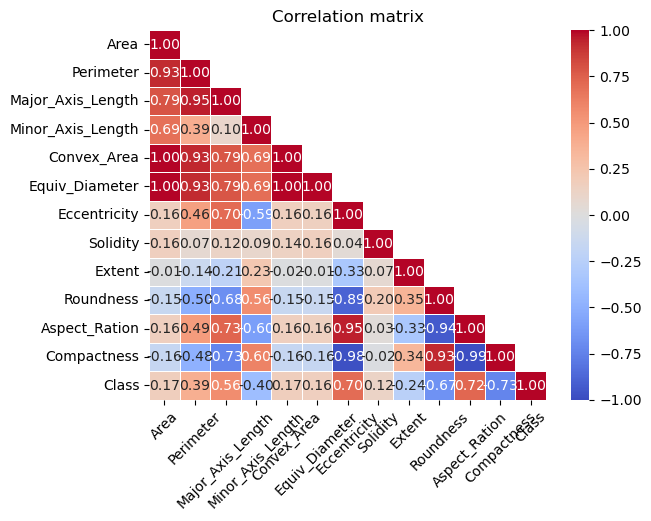

In [15]:
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr,dtype=bool),k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', linewidth=.5, center=0, vmax=1,vmin=-1,cmap='coolwarm')
plt.xticks(rotation=45)
plt.title("Correlation matrix")

## Distribution

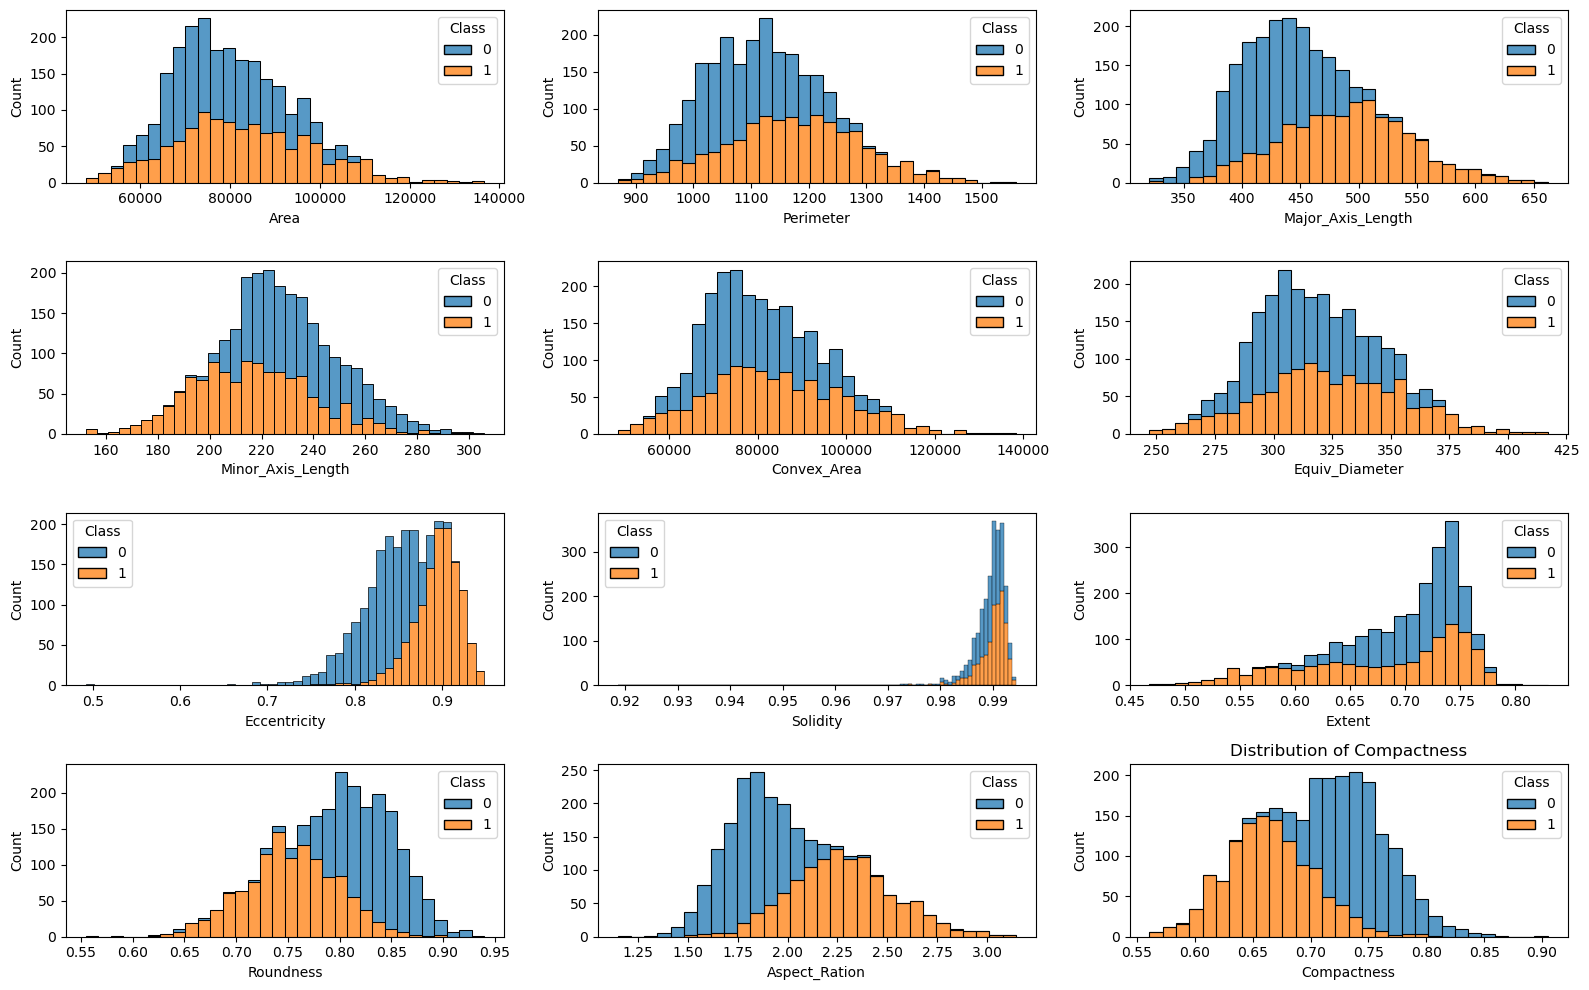

In [63]:
fig,axes = plt.subplots(4,3,figsize=(16,10))
for ax,col in zip(axes.flatten(),num_cols):
    sns.histplot(df,x=col,ax=ax,hue='Class',multiple='stack')
    plt.title(f'Distribution of {col}')
plt.tight_layout()

Text(0.5, 1.0, 'Countplot of Class')

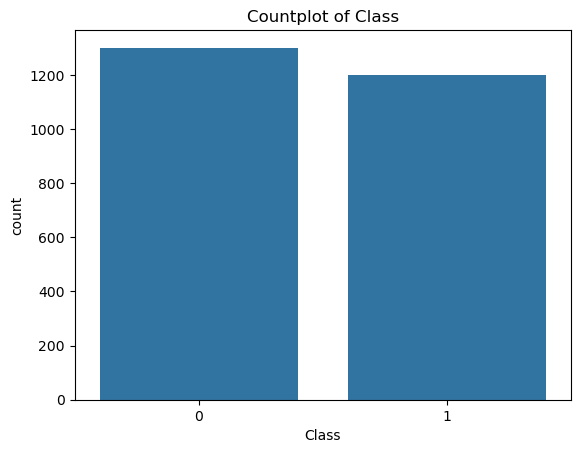

In [62]:
sns.countplot(df,x='Class')
plt.title("Countplot of Class")

In [66]:
df.groupby('Class').agg(['mean','std']).T

Class                              0             1
Area              mean  78423.154615  83079.542500
                  std   11246.499728  15519.323847
Perimeter         mean   1089.522488   1174.431919
                  std      83.128407    116.793253
Major_Axis_Length mean    426.272615    489.458501
                  std      37.196923     54.904345
Minor_Axis_Length mean    234.776929    216.064413
                  std      19.500795     23.173521
Convex_Area       mean  79286.488462  83914.813333
                  std   11350.508104  15624.711959
Equiv_Diameter    mean    315.193332    323.820202
                  std      22.472502     30.354631
Eccentricity      mean      0.830538      0.893749
                  std       0.036333      0.027247
Solidity          mean      0.989080      0.989938
                  std       0.003391      0.003550
Extent            mean      0.707018      0.678240
                  std       0.040698      0.074216
Roundness         mean      0.827499      0.752570
                  std       0.037485      0.045543
Aspect_Ration     mean      1.822609      2.279054
                  std       0.168501      0.262546
Compactness       mean      0.741163      0.663991
                  std       0.034388      0.038586

## Outliers

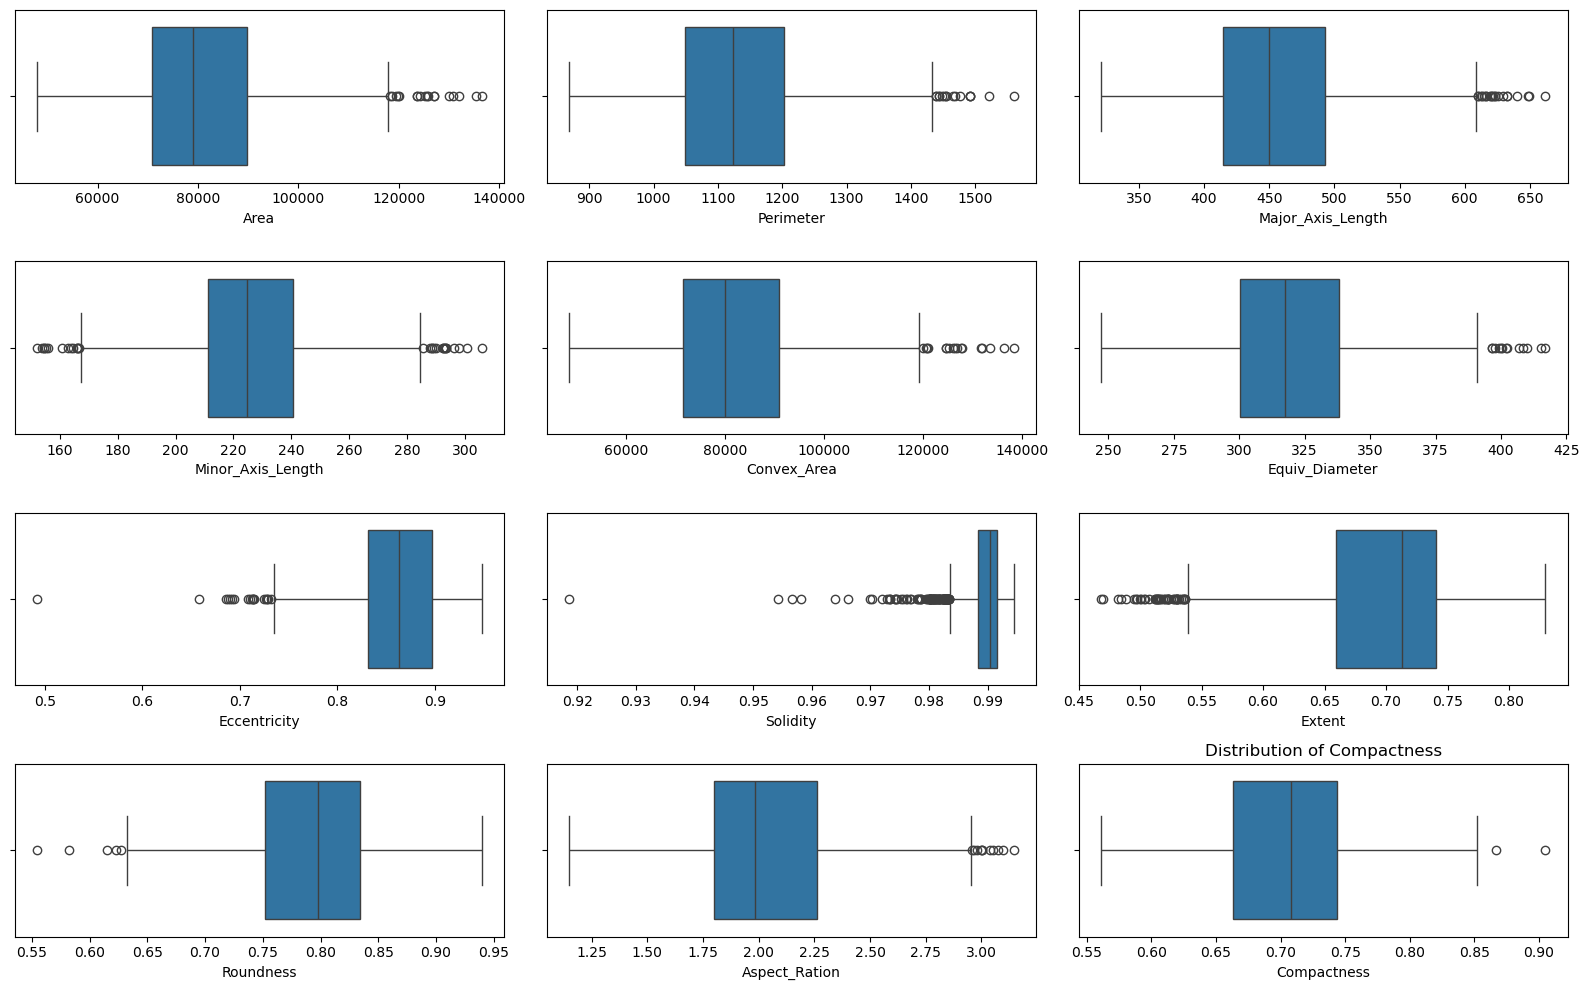

In [67]:
fig,axes = plt.subplots(4,3,figsize=(16,10))
for ax,col in zip(axes.flatten(),num_cols):
    sns.boxplot(df,x=col,ax=ax)
    plt.title(f'Distribution of {col}')
plt.tight_layout()

# Train

In [3]:
df['Class'] = df['Class'].replace('Çerçevelik',0)
df['Class'] = df['Class'].replace('Ürgüp Sivrisi',1)
df['Class'] = pd.to_numeric(df['Class'])

In [8]:
X = df.drop(columns=['Class'])
y = df['Class']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

X = X_train
y = y_train

In [9]:
def train_pipe(model):
    pipe = Pipeline([
        ('scalar',StandardScaler()),
        ('model',model)
    ])
    return pipe

In [10]:
def outlier_process(X):
    quartile_1, quartile_3 = np.percentile(X, [25,75])
    iqr = quartile_3 - quartile_1
    ub = quartile_3 + 1.5*iqr
    lb = quartile_1 - 1.5*iqr
    return ub,lb

In [11]:
def training(pipe, outlier=False):
    skf = StratifiedKFold()
    train_accs = []
    test_accs = []
    coeffs = []
    for i,(train_index, test_index) in enumerate(skf.split(X,y)):
        X_train, X_test = X.iloc[train_index],X.iloc[test_index]
        y_train, y_test = y.iloc[train_index],y.iloc[test_index]
        if outlier:
            ub,lb = outlier_process(X_train)
            X_train = np.clip(X_train,lb,ub)
            X_test = np.clip(X_test,lb,ub)
        y_pred = pipe.fit(X_train,y_train).predict(X_test)
        y_train_pred = pipe.predict(X_train)
        train_accs.append(roc_auc_score(y_train,y_train_pred))
        test_accs.append(roc_auc_score(y_test,y_pred))
        if isinstance(pipe['model'], LogisticRegression):
            coeffs.append(pipe['model'].coef_[0])
    if isinstance(pipe['model'], LogisticRegression):
            print(pd.DataFrame(coeffs, columns=X_train.columns).agg(['mean','std']).T)
    return np.mean(train_accs), np.mean(test_accs)
    

In [12]:
def hyper_tune(train_pipe,n_trials=100,outlier=False):
    def objective(trial):
        params = {
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 200, 800),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
    }
        train_pipe.set_params(**{f'model__{k}':v for k,v in params.items()})
        train_score,test_score = training(train_pipe,outlier)
        print(f'Train_Score:{train_score}')
        return test_score
    
    study = optuna.create_study(direction='maximize')  
    study.optimize(objective, n_trials=n_trials) 
    print(study.best_value,study.best_params)


## W/O Outlier removal

### Logisitc regression

In [47]:
log_pipe = train_pipe(LogisticRegression())

In [53]:
training(log_pipe)

                       mean       std
Area               2.097052  0.170372
Perimeter         -1.467318  0.086859
Major_Axis_Length -0.021799  0.105630
Minor_Axis_Length -0.736244  0.248275
Convex_Area        1.929815  0.148267
Equiv_Diameter    -2.022454  0.134112
Eccentricity      -1.544051  0.111709
Solidity           0.640449  0.053687
Extent             0.045373  0.092632
Roundness         -1.144428  0.230890
Aspect_Ration      1.809079  0.203049
Compactness       -1.791229  0.154340


(np.float64(0.8802564102564103), np.float64(0.8766987179487179))

### Xgboost

In [14]:
xgb_pipe = train_pipe(XGBClassifier())

In [17]:
training(xgb_pipe)

(np.float64(0.9998958333333334), np.float64(0.877051282051282))

In [59]:
hyper_tune(xgb_pipe)

[I 2026-10-09 19:44:21,783] A new study created in memory with name: no-name-5575a628-f57f-4dd2-83bf-7d0d0c9527ab
[I 2026-10-09 19:44:26,380] Trial 0 finished with value: 0.8723076923076922 and parameters: {'max_depth': 6, 'learning_rate': 0.14487667486487849, 'n_estimators': 661, 'subsample': 0.7375885055445289, 'colsample_bytree': 0.5714608807112429, 'min_child_weight': 15, 'gamma': 1.8530364448050152, 'reg_lambda': 0.06590249601544035, 'reg_alpha': 0.002823821580770069}. Best is trial 0 with value: 0.8723076923076922.


Train_Score:0.9221233974358973


[I 2026-10-09 19:44:35,087] Trial 1 finished with value: 0.8753525641025639 and parameters: {'max_depth': 9, 'learning_rate': 0.1950751284867648, 'n_estimators': 755, 'subsample': 0.7383027522749328, 'colsample_bytree': 0.6334882859482991, 'min_child_weight': 7, 'gamma': 0.5019094143268071, 'reg_lambda': 0.9828931951437041, 'reg_alpha': 0.19789317066680667}. Best is trial 1 with value: 0.8753525641025639.


Train_Score:0.9897195512820514


[I 2026-10-09 19:44:36,698] Trial 2 finished with value: 0.8800000000000001 and parameters: {'max_depth': 8, 'learning_rate': 0.2328402350187, 'n_estimators': 295, 'subsample': 0.7299347102732845, 'colsample_bytree': 0.8764413612255979, 'min_child_weight': 14, 'gamma': 1.6586338204352324, 'reg_lambda': 0.5697905575031049, 'reg_alpha': 6.970826445984463}. Best is trial 2 with value: 0.8800000000000001.


Train_Score:0.8931009615384615


[I 2026-10-09 19:44:41,389] Trial 3 finished with value: 0.8807371794871794 and parameters: {'max_depth': 7, 'learning_rate': 0.0917772980383341, 'n_estimators': 635, 'subsample': 0.9396402427513524, 'colsample_bytree': 0.9790513082574912, 'min_child_weight': 8, 'gamma': 1.0262106985824322, 'reg_lambda': 0.013374884874881433, 'reg_alpha': 0.12925951467934718}. Best is trial 3 with value: 0.8807371794871794.


Train_Score:0.9375721153846154


[I 2026-10-09 19:44:44,974] Trial 4 finished with value: 0.8809294871794873 and parameters: {'max_depth': 3, 'learning_rate': 0.013968207488647553, 'n_estimators': 355, 'subsample': 0.9159995074167606, 'colsample_bytree': 0.5441163824110039, 'min_child_weight': 5, 'gamma': 0.02532694011899539, 'reg_lambda': 0.4166302732969024, 'reg_alpha': 0.24139136349391185}. Best is trial 4 with value: 0.8809294871794873.


Train_Score:0.8998637820512819


[I 2026-10-09 19:44:46,531] Trial 5 finished with value: 0.8807692307692306 and parameters: {'max_depth': 3, 'learning_rate': 0.07968898699653854, 'n_estimators': 203, 'subsample': 0.9652426954051868, 'colsample_bytree': 0.9773395702936105, 'min_child_weight': 5, 'gamma': 1.8374819784165202, 'reg_lambda': 0.5439765709862636, 'reg_alpha': 0.018461619855383877}. Best is trial 4 with value: 0.8809294871794873.


Train_Score:0.9037419871794873


[I 2026-10-09 19:44:49,812] Trial 6 finished with value: 0.8818589743589744 and parameters: {'max_depth': 10, 'learning_rate': 0.19879196624102916, 'n_estimators': 695, 'subsample': 0.9671884187902512, 'colsample_bytree': 0.8358949529059208, 'min_child_weight': 7, 'gamma': 3.886747209478367, 'reg_lambda': 1.187374026738965, 'reg_alpha': 0.041639611451186075}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.906338141025641


[I 2026-10-09 19:44:56,585] Trial 7 finished with value: 0.8792948717948719 and parameters: {'max_depth': 7, 'learning_rate': 0.02034456099121079, 'n_estimators': 585, 'subsample': 0.7350401139296356, 'colsample_bytree': 0.8713597586739666, 'min_child_weight': 9, 'gamma': 2.351616351425899, 'reg_lambda': 0.03941509805172262, 'reg_alpha': 0.015963928604746574}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.9141025641025641


[I 2026-10-09 19:45:00,517] Trial 8 finished with value: 0.8759935897435897 and parameters: {'max_depth': 9, 'learning_rate': 0.11043532702043307, 'n_estimators': 271, 'subsample': 0.7073745120185497, 'colsample_bytree': 0.6935313313206752, 'min_child_weight': 13, 'gamma': 0.7902217654741617, 'reg_lambda': 1.8403103026954828, 'reg_alpha': 0.0337434004287834}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.9290705128205128


[I 2026-10-09 19:45:04,379] Trial 9 finished with value: 0.8786538461538461 and parameters: {'max_depth': 9, 'learning_rate': 0.036736871890867086, 'n_estimators': 576, 'subsample': 0.9476511814208819, 'colsample_bytree': 0.6456926268204592, 'min_child_weight': 7, 'gamma': 3.7204673046452887, 'reg_lambda': 0.8482795656925936, 'reg_alpha': 0.23932389807581964}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.9031891025641026


[I 2026-10-09 19:45:08,082] Trial 10 finished with value: 0.8804807692307692 and parameters: {'max_depth': 5, 'learning_rate': 0.05816043157556423, 'n_estimators': 668, 'subsample': 0.8892501775612213, 'colsample_bytree': 0.6817795221210469, 'min_child_weight': 3, 'gamma': 3.7953602320213773, 'reg_lambda': 4.034282027540451, 'reg_alpha': 0.3643810668611032}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.9009054487179486


[I 2026-10-09 19:45:12,726] Trial 11 finished with value: 0.8752884615384616 and parameters: {'max_depth': 3, 'learning_rate': 0.10130705387486014, 'n_estimators': 474, 'subsample': 0.9389044659840632, 'colsample_bytree': 0.581583049381184, 'min_child_weight': 6, 'gamma': 0.01340051972046441, 'reg_lambda': 0.7574773534690317, 'reg_alpha': 1.0889768907981618}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.9449679487179488


[I 2026-10-09 19:45:16,643] Trial 12 finished with value: 0.878429487179487 and parameters: {'max_depth': 7, 'learning_rate': 0.10025891025789782, 'n_estimators': 662, 'subsample': 0.9441691884507616, 'colsample_bytree': 0.6813035955820913, 'min_child_weight': 8, 'gamma': 1.533274050362305, 'reg_lambda': 6.308001185535439, 'reg_alpha': 0.023643604377616718}. Best is trial 6 with value: 0.8818589743589744.


Train_Score:0.9135176282051283


[I 2026-10-09 19:45:22,059] Trial 13 finished with value: 0.8850320512820513 and parameters: {'max_depth': 10, 'learning_rate': 0.07638611904692504, 'n_estimators': 736, 'subsample': 0.9693023743858623, 'colsample_bytree': 0.8926669737788503, 'min_child_weight': 4, 'gamma': 0.669870394364068, 'reg_lambda': 0.7197552654372545, 'reg_alpha': 0.6167080076064607}. Best is trial 13 with value: 0.8850320512820513.


Train_Score:0.950040064102564


[I 2026-10-09 19:45:26,718] Trial 14 finished with value: 0.8853846153846154 and parameters: {'max_depth': 9, 'learning_rate': 0.05323266942755898, 'n_estimators': 763, 'subsample': 0.9793826957078011, 'colsample_bytree': 0.9001709388398962, 'min_child_weight': 2, 'gamma': 0.6123065663510214, 'reg_lambda': 1.3347339372112699, 'reg_alpha': 9.469066404098353}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.8995993589743589


[I 2026-10-09 19:45:31,293] Trial 15 finished with value: 0.8847435897435897 and parameters: {'max_depth': 7, 'learning_rate': 0.05503815845661036, 'n_estimators': 597, 'subsample': 0.9994363379957097, 'colsample_bytree': 0.8948145259004535, 'min_child_weight': 2, 'gamma': 0.0924155185799046, 'reg_lambda': 0.24205524126923333, 'reg_alpha': 8.940611093385469}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9043669871794873


[I 2026-10-09 19:45:34,789] Trial 16 finished with value: 0.8824358974358975 and parameters: {'max_depth': 9, 'learning_rate': 0.1871702815981913, 'n_estimators': 682, 'subsample': 0.9855334920647291, 'colsample_bytree': 0.9219466134192398, 'min_child_weight': 2, 'gamma': 1.2946985805629956, 'reg_lambda': 0.3390345489875127, 'reg_alpha': 1.232269743662819}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9317948717948716


[I 2026-10-09 19:45:43,156] Trial 17 finished with value: 0.8835897435897436 and parameters: {'max_depth': 10, 'learning_rate': 0.03516363673721188, 'n_estimators': 710, 'subsample': 0.9411468736383268, 'colsample_bytree': 0.7626310315363094, 'min_child_weight': 1, 'gamma': 0.4082866559939232, 'reg_lambda': 6.829780295333326, 'reg_alpha': 2.216971241392549}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9301923076923077


[I 2026-10-09 19:45:52,042] Trial 18 finished with value: 0.8838141025641025 and parameters: {'max_depth': 10, 'learning_rate': 0.04250364520615409, 'n_estimators': 776, 'subsample': 0.9576101814210051, 'colsample_bytree': 0.8010885630894063, 'min_child_weight': 2, 'gamma': 0.3398873725440607, 'reg_lambda': 0.13199473287218982, 'reg_alpha': 0.24509060737083416}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9889823717948719


[I 2026-10-09 19:45:56,266] Trial 19 finished with value: 0.8793589743589744 and parameters: {'max_depth': 9, 'learning_rate': 0.06229500034221467, 'n_estimators': 612, 'subsample': 0.9413202346131944, 'colsample_bytree': 0.8179649497594559, 'min_child_weight': 5, 'gamma': 1.0311238290037787, 'reg_lambda': 1.5147409655007298, 'reg_alpha': 1.978165510544958}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9167307692307691


[I 2026-10-09 19:46:03,734] Trial 20 finished with value: 0.8784935897435897 and parameters: {'max_depth': 10, 'learning_rate': 0.08053680823940151, 'n_estimators': 611, 'subsample': 0.991588424084263, 'colsample_bytree': 0.8472353249902834, 'min_child_weight': 5, 'gamma': 0.2382813645794607, 'reg_lambda': 1.1464114956361058, 'reg_alpha': 0.17724281557697463}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9780208333333335


[I 2026-10-09 19:46:10,995] Trial 21 finished with value: 0.8809294871794873 and parameters: {'max_depth': 7, 'learning_rate': 0.04298832957942483, 'n_estimators': 788, 'subsample': 0.933237506384373, 'colsample_bytree': 0.865976248407107, 'min_child_weight': 3, 'gamma': 0.1578199117872266, 'reg_lambda': 1.3364596115192373, 'reg_alpha': 5.035445259888245}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9201362179487178


[I 2026-10-09 19:46:15,770] Trial 22 finished with value: 0.8837179487179487 and parameters: {'max_depth': 8, 'learning_rate': 0.054862335686417164, 'n_estimators': 647, 'subsample': 0.958335980196842, 'colsample_bytree': 0.9144391791449109, 'min_child_weight': 1, 'gamma': 0.8813276714627586, 'reg_lambda': 0.4630579719073875, 'reg_alpha': 1.4181364110512618}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9391506410256412


[I 2026-10-09 19:46:20,056] Trial 23 finished with value: 0.88375 and parameters: {'max_depth': 10, 'learning_rate': 0.082642361940557, 'n_estimators': 782, 'subsample': 0.8553856644849014, 'colsample_bytree': 0.779552259230681, 'min_child_weight': 6, 'gamma': 0.6722540257487348, 'reg_lambda': 0.6599966037568524, 'reg_alpha': 8.51245357547233}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.8980608974358976


[I 2026-10-09 19:46:24,893] Trial 24 finished with value: 0.8828205128205129 and parameters: {'max_depth': 9, 'learning_rate': 0.05583558726998491, 'n_estimators': 728, 'subsample': 0.9634905023273237, 'colsample_bytree': 0.8331457125808769, 'min_child_weight': 2, 'gamma': 1.505543571159854, 'reg_lambda': 1.6632127070746714, 'reg_alpha': 0.7715432132993376}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9263942307692309


[I 2026-10-09 19:46:28,148] Trial 25 finished with value: 0.8825961538461538 and parameters: {'max_depth': 7, 'learning_rate': 0.05214214550846446, 'n_estimators': 477, 'subsample': 0.9899318873647005, 'colsample_bytree': 0.9392130549142392, 'min_child_weight': 5, 'gamma': 0.7766386855580321, 'reg_lambda': 0.7115237725301371, 'reg_alpha': 9.20828530352502}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.8993028846153847


[I 2026-10-09 19:46:33,776] Trial 26 finished with value: 0.8825 and parameters: {'max_depth': 10, 'learning_rate': 0.025465447520703482, 'n_estimators': 734, 'subsample': 0.9792169700888431, 'colsample_bytree': 0.8713015058434326, 'min_child_weight': 1, 'gamma': 1.739343914602611, 'reg_lambda': 0.5947406590814885, 'reg_alpha': 3.013066938288127}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.907235576923077


[I 2026-10-09 19:46:42,250] Trial 27 finished with value: 0.8826923076923079 and parameters: {'max_depth': 8, 'learning_rate': 0.021547335341782225, 'n_estimators': 708, 'subsample': 0.9391821356899307, 'colsample_bytree': 0.8873487536468735, 'min_child_weight': 2, 'gamma': 0.16278592629357114, 'reg_lambda': 0.257135089121658, 'reg_alpha': 7.679225560827226}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9073157051282053


[I 2026-10-09 19:46:46,667] Trial 28 finished with value: 0.8800961538461539 and parameters: {'max_depth': 10, 'learning_rate': 0.201735516465845, 'n_estimators': 793, 'subsample': 0.9848575496680569, 'colsample_bytree': 0.936913073674098, 'min_child_weight': 4, 'gamma': 0.4251194320502155, 'reg_lambda': 0.8758380370458541, 'reg_alpha': 1.150144785579104}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9497676282051284


[I 2026-10-09 19:46:50,384] Trial 29 finished with value: 0.8841025641025639 and parameters: {'max_depth': 8, 'learning_rate': 0.08403296581572982, 'n_estimators': 672, 'subsample': 0.9453891694137523, 'colsample_bytree': 0.9809334972791145, 'min_child_weight': 3, 'gamma': 1.4388774280659906, 'reg_lambda': 0.5104461533959139, 'reg_alpha': 3.772098571598134}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9052243589743589


[I 2026-10-09 19:46:55,116] Trial 30 finished with value: 0.8828846153846154 and parameters: {'max_depth': 10, 'learning_rate': 0.0382637422967884, 'n_estimators': 735, 'subsample': 0.9247735672806088, 'colsample_bytree': 0.9500850657779891, 'min_child_weight': 5, 'gamma': 0.8950420330899043, 'reg_lambda': 0.6932750034154561, 'reg_alpha': 9.662281343312571}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.8976201923076923


[I 2026-10-09 19:46:59,664] Trial 31 finished with value: 0.8828846153846154 and parameters: {'max_depth': 9, 'learning_rate': 0.06724576177355046, 'n_estimators': 779, 'subsample': 0.9810109078175223, 'colsample_bytree': 0.9516019946983238, 'min_child_weight': 2, 'gamma': 1.1892610358143454, 'reg_lambda': 1.5306188712952151, 'reg_alpha': 2.6435406508053165}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9122916666666667


[I 2026-10-09 19:47:03,038] Trial 32 finished with value: 0.8826923076923077 and parameters: {'max_depth': 7, 'learning_rate': 0.08454164569251232, 'n_estimators': 554, 'subsample': 0.9265982800174694, 'colsample_bytree': 0.9004077105101398, 'min_child_weight': 2, 'gamma': 0.6560358756263256, 'reg_lambda': 0.2974977001816697, 'reg_alpha': 6.749451160107847}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9023237179487179


[I 2026-10-09 19:47:07,087] Trial 33 finished with value: 0.8838461538461537 and parameters: {'max_depth': 9, 'learning_rate': 0.10986408883430758, 'n_estimators': 753, 'subsample': 0.9750858220693092, 'colsample_bytree': 0.860214933594517, 'min_child_weight': 2, 'gamma': 0.6173322786887973, 'reg_lambda': 8.556256267880151, 'reg_alpha': 7.36131100698548}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9013141025641026


[I 2026-10-09 19:47:13,673] Trial 34 finished with value: 0.8833653846153847 and parameters: {'max_depth': 9, 'learning_rate': 0.028891357371536617, 'n_estimators': 741, 'subsample': 0.9963844342891363, 'colsample_bytree': 0.9679588478564009, 'min_child_weight': 2, 'gamma': 0.4753127239624456, 'reg_lambda': 1.9370048833700368, 'reg_alpha': 4.272264228450902}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9123397435897436


[I 2026-10-09 19:47:18,503] Trial 35 finished with value: 0.8821153846153846 and parameters: {'max_depth': 7, 'learning_rate': 0.059247628011808856, 'n_estimators': 468, 'subsample': 0.9897818679882032, 'colsample_bytree': 0.9103981829779112, 'min_child_weight': 1, 'gamma': 0.06745444365569943, 'reg_lambda': 0.1959369944797072, 'reg_alpha': 3.14102769575918}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9438461538461539


[I 2026-10-09 19:47:23,156] Trial 36 finished with value: 0.8812820512820514 and parameters: {'max_depth': 9, 'learning_rate': 0.08779720751698979, 'n_estimators': 762, 'subsample': 0.9849275062632399, 'colsample_bytree': 0.9327030285423883, 'min_child_weight': 3, 'gamma': 0.8439081788652194, 'reg_lambda': 4.316815449758677, 'reg_alpha': 1.1009922297040142}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9278285256410257


[I 2026-10-09 19:47:29,477] Trial 37 finished with value: 0.8819871794871794 and parameters: {'max_depth': 9, 'learning_rate': 0.08349090312334301, 'n_estimators': 780, 'subsample': 0.9657043944013924, 'colsample_bytree': 0.895905785351323, 'min_child_weight': 3, 'gamma': 0.10831489710187481, 'reg_lambda': 0.3324028936563942, 'reg_alpha': 3.2541727594621643}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9439503205128206


[I 2026-10-09 19:47:37,283] Trial 38 finished with value: 0.878525641025641 and parameters: {'max_depth': 9, 'learning_rate': 0.07393991360792053, 'n_estimators': 730, 'subsample': 0.9423201334818262, 'colsample_bytree': 0.8967559831846923, 'min_child_weight': 5, 'gamma': 0.3029108864912182, 'reg_lambda': 1.9692906101942367, 'reg_alpha': 1.0535266600014248}. Best is trial 14 with value: 0.8853846153846154.


Train_Score:0.9622115384615384


[I 2026-10-09 19:47:41,981] Trial 39 finished with value: 0.8859935897435897 and parameters: {'max_depth': 7, 'learning_rate': 0.04607340737716318, 'n_estimators': 587, 'subsample': 0.9917989513542832, 'colsample_bytree': 0.8394190739154502, 'min_child_weight': 2, 'gamma': 0.16463465549902445, 'reg_lambda': 0.12224844043018801, 'reg_alpha': 8.551349514256}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9041666666666668


[I 2026-10-09 19:47:46,231] Trial 40 finished with value: 0.885801282051282 and parameters: {'max_depth': 10, 'learning_rate': 0.05162851987579323, 'n_estimators': 698, 'subsample': 0.9871946099510852, 'colsample_bytree': 0.8542328685863085, 'min_child_weight': 2, 'gamma': 0.9406187746868067, 'reg_lambda': 1.3690901029946398, 'reg_alpha': 7.851181522000141}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9005608974358974


[I 2026-10-09 19:47:51,014] Trial 41 finished with value: 0.881602564102564 and parameters: {'max_depth': 6, 'learning_rate': 0.05526599270081558, 'n_estimators': 675, 'subsample': 0.9549337356878289, 'colsample_bytree': 0.8506698054462655, 'min_child_weight': 2, 'gamma': 0.3885686099192504, 'reg_lambda': 0.14826290338566034, 'reg_alpha': 3.3429237364177102}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9229727564102564


[I 2026-10-09 19:47:56,356] Trial 42 finished with value: 0.8834615384615384 and parameters: {'max_depth': 9, 'learning_rate': 0.03637512242252273, 'n_estimators': 685, 'subsample': 0.9849312404686219, 'colsample_bytree': 0.8646973772630101, 'min_child_weight': 1, 'gamma': 0.6894278854923583, 'reg_lambda': 0.9703515217006039, 'reg_alpha': 4.444726929017561}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9108253205128205


[I 2026-10-09 19:48:01,646] Trial 43 finished with value: 0.8841987179487181 and parameters: {'max_depth': 10, 'learning_rate': 0.07387717111154164, 'n_estimators': 733, 'subsample': 0.967163398693525, 'colsample_bytree': 0.864520488847316, 'min_child_weight': 2, 'gamma': 0.8563834520617049, 'reg_lambda': 1.8729288438998681, 'reg_alpha': 0.3068161126610446}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9525240384615385


[I 2026-10-09 19:48:06,120] Trial 44 finished with value: 0.8834615384615384 and parameters: {'max_depth': 8, 'learning_rate': 0.06041289096774084, 'n_estimators': 612, 'subsample': 0.9803452363661486, 'colsample_bytree': 0.9526194155148556, 'min_child_weight': 2, 'gamma': 0.16989407919452854, 'reg_lambda': 0.33587340390020276, 'reg_alpha': 8.481294436463081}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9058573717948718


[I 2026-10-09 19:48:10,044] Trial 45 finished with value: 0.8819230769230769 and parameters: {'max_depth': 10, 'learning_rate': 0.0695857767683407, 'n_estimators': 659, 'subsample': 0.9976133047619437, 'colsample_bytree': 0.8452033850691449, 'min_child_weight': 2, 'gamma': 0.6896030939952272, 'reg_lambda': 0.3232891113995569, 'reg_alpha': 6.641661118425138}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9038701923076923


[I 2026-10-09 19:48:13,695] Trial 46 finished with value: 0.880224358974359 and parameters: {'max_depth': 6, 'learning_rate': 0.0806711022789077, 'n_estimators': 503, 'subsample': 0.9819832424611248, 'colsample_bytree': 0.8873505422044615, 'min_child_weight': 2, 'gamma': 0.08878073709850201, 'reg_lambda': 0.5564708072069019, 'reg_alpha': 6.85309577230744}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9094391025641025


[I 2026-10-09 19:48:18,931] Trial 47 finished with value: 0.8842628205128206 and parameters: {'max_depth': 9, 'learning_rate': 0.0459261282207765, 'n_estimators': 793, 'subsample': 0.9926632308597779, 'colsample_bytree': 0.9649643947542629, 'min_child_weight': 4, 'gamma': 0.4334884572575357, 'reg_lambda': 2.5564180703944412, 'reg_alpha': 6.41738376102905}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9033733974358974


[I 2026-10-09 19:48:23,635] Trial 48 finished with value: 0.8829487179487179 and parameters: {'max_depth': 10, 'learning_rate': 0.051500140169820505, 'n_estimators': 743, 'subsample': 0.9341134956404148, 'colsample_bytree': 0.8370272618084637, 'min_child_weight': 3, 'gamma': 1.1582973313684528, 'reg_lambda': 0.7978224017316183, 'reg_alpha': 3.3402135233747683}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9089983974358974


[I 2026-10-09 19:48:29,074] Trial 49 finished with value: 0.8838461538461537 and parameters: {'max_depth': 10, 'learning_rate': 0.040032401100429035, 'n_estimators': 645, 'subsample': 0.9585225808844527, 'colsample_bytree': 0.8625838827430896, 'min_child_weight': 1, 'gamma': 0.32526289511782447, 'reg_lambda': 1.619504609793538, 'reg_alpha': 6.076417722328457}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9101923076923077


[I 2026-10-09 19:48:34,420] Trial 50 finished with value: 0.8826282051282052 and parameters: {'max_depth': 8, 'learning_rate': 0.028823658993106356, 'n_estimators': 538, 'subsample': 0.9892281689995488, 'colsample_bytree': 0.8316754259352734, 'min_child_weight': 3, 'gamma': 0.3001547519371843, 'reg_lambda': 0.27730760423021933, 'reg_alpha': 6.5057595759010916}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9065224358974359


[I 2026-10-09 19:48:39,337] Trial 51 finished with value: 0.8847435897435897 and parameters: {'max_depth': 10, 'learning_rate': 0.07129131150198574, 'n_estimators': 769, 'subsample': 0.9262145403511224, 'colsample_bytree': 0.8935448581906025, 'min_child_weight': 1, 'gamma': 0.40174306251999053, 'reg_lambda': 1.1836993252016277, 'reg_alpha': 6.924433176286301}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9072836538461537


[I 2026-10-09 19:48:44,456] Trial 52 finished with value: 0.8813141025641027 and parameters: {'max_depth': 9, 'learning_rate': 0.07935591288911698, 'n_estimators': 737, 'subsample': 0.9136054861989567, 'colsample_bytree': 0.9512640323574588, 'min_child_weight': 2, 'gamma': 0.3148562541152799, 'reg_lambda': 3.049348683401563, 'reg_alpha': 4.604465252937415}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9193429487179487


[I 2026-10-09 19:48:49,504] Trial 53 finished with value: 0.8830769230769231 and parameters: {'max_depth': 10, 'learning_rate': 0.04390038423080122, 'n_estimators': 750, 'subsample': 0.9940840841845726, 'colsample_bytree': 0.8461943180431175, 'min_child_weight': 2, 'gamma': 0.7094710853299497, 'reg_lambda': 0.9611181912496639, 'reg_alpha': 5.584258171553605}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9047916666666668


[I 2026-10-09 19:48:53,820] Trial 54 finished with value: 0.8834615384615384 and parameters: {'max_depth': 7, 'learning_rate': 0.06256979099672103, 'n_estimators': 578, 'subsample': 0.9715365647911859, 'colsample_bytree': 0.8082619295257296, 'min_child_weight': 2, 'gamma': 0.224107433360676, 'reg_lambda': 0.09473279292402492, 'reg_alpha': 6.89042207217884}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9063301282051281


[I 2026-10-09 19:48:58,249] Trial 55 finished with value: 0.8859615384615385 and parameters: {'max_depth': 7, 'learning_rate': 0.043821351906287685, 'n_estimators': 654, 'subsample': 0.9921654384048398, 'colsample_bytree': 0.8031573271665264, 'min_child_weight': 3, 'gamma': 0.4907544654432545, 'reg_lambda': 0.03552100384502448, 'reg_alpha': 6.866741861050784}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9038060897435898


[I 2026-10-09 19:49:02,376] Trial 56 finished with value: 0.8838461538461537 and parameters: {'max_depth': 9, 'learning_rate': 0.0585951733728924, 'n_estimators': 670, 'subsample': 0.9836233893846535, 'colsample_bytree': 0.926719857215977, 'min_child_weight': 3, 'gamma': 0.5176140097855689, 'reg_lambda': 0.576950403180107, 'reg_alpha': 9.893818196095891}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.899551282051282


[I 2026-10-09 19:49:06,921] Trial 57 finished with value: 0.8846474358974359 and parameters: {'max_depth': 10, 'learning_rate': 0.051774171005319884, 'n_estimators': 662, 'subsample': 0.9286746035240381, 'colsample_bytree': 0.840402114330258, 'min_child_weight': 3, 'gamma': 0.4298573287907171, 'reg_lambda': 2.7869561915199084, 'reg_alpha': 9.449541566367284}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.899911858974359


[I 2026-10-09 19:49:10,957] Trial 58 finished with value: 0.8841987179487178 and parameters: {'max_depth': 10, 'learning_rate': 0.05098097101166086, 'n_estimators': 706, 'subsample': 0.9941942873849655, 'colsample_bytree': 0.9105155939134812, 'min_child_weight': 2, 'gamma': 1.4609313942302518, 'reg_lambda': 0.45822836686482726, 'reg_alpha': 7.681089861784495}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.8992708333333332


[I 2026-10-09 19:49:15,475] Trial 59 finished with value: 0.8850641025641026 and parameters: {'max_depth': 10, 'learning_rate': 0.051392425270993025, 'n_estimators': 723, 'subsample': 0.9463301086511815, 'colsample_bytree': 0.8889445054056412, 'min_child_weight': 1, 'gamma': 1.0661228097856394, 'reg_lambda': 1.812483474144621, 'reg_alpha': 5.865406255189424}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9031891025641027


[I 2026-10-09 19:49:20,486] Trial 60 finished with value: 0.8826282051282052 and parameters: {'max_depth': 10, 'learning_rate': 0.07259977200170505, 'n_estimators': 763, 'subsample': 0.9988448524110212, 'colsample_bytree': 0.833439392134213, 'min_child_weight': 2, 'gamma': 0.3011681216293226, 'reg_lambda': 1.5691430660066017, 'reg_alpha': 3.7948000063859886}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9207532051282051


[I 2026-10-09 19:49:25,486] Trial 61 finished with value: 0.885897435897436 and parameters: {'max_depth': 10, 'learning_rate': 0.0530830615979159, 'n_estimators': 769, 'subsample': 0.9605552562150627, 'colsample_bytree': 0.911260538173801, 'min_child_weight': 2, 'gamma': 0.4542629735952165, 'reg_lambda': 2.0222649588526083, 'reg_alpha': 7.861738302441686}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9031891025641026


[I 2026-10-09 19:49:29,914] Trial 62 finished with value: 0.8831089743589745 and parameters: {'max_depth': 10, 'learning_rate': 0.07642272112248877, 'n_estimators': 670, 'subsample': 0.9810660809607524, 'colsample_bytree': 0.8926164685794761, 'min_child_weight': 3, 'gamma': 0.22357978271499493, 'reg_lambda': 3.1733383936774837, 'reg_alpha': 6.635661219777573}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9068509615384615


[I 2026-10-09 19:49:34,920] Trial 63 finished with value: 0.8859294871794872 and parameters: {'max_depth': 9, 'learning_rate': 0.05289604522931296, 'n_estimators': 765, 'subsample': 0.967201137848562, 'colsample_bytree': 0.9617850519530389, 'min_child_weight': 1, 'gamma': 0.44990629523559017, 'reg_lambda': 1.0770934480675922, 'reg_alpha': 9.742020210349079}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9019551282051281


[I 2026-10-09 19:49:39,297] Trial 64 finished with value: 0.8857692307692308 and parameters: {'max_depth': 9, 'learning_rate': 0.04635530494225951, 'n_estimators': 731, 'subsample': 0.9889470251479175, 'colsample_bytree': 0.8516852708862658, 'min_child_weight': 2, 'gamma': 1.075141008638056, 'reg_lambda': 1.4261242378162238, 'reg_alpha': 9.904856283763744}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.8975


[I 2026-10-09 19:49:44,764] Trial 65 finished with value: 0.8813461538461539 and parameters: {'max_depth': 9, 'learning_rate': 0.04615629363125991, 'n_estimators': 701, 'subsample': 0.952603667304306, 'colsample_bytree': 0.8975782798093922, 'min_child_weight': 3, 'gamma': 0.427388950461153, 'reg_lambda': 1.1888109463826482, 'reg_alpha': 4.400110189607231}. Best is trial 39 with value: 0.8859935897435897.


Train_Score:0.9130528846153846


[I 2026-10-09 19:49:49,620] Trial 66 finished with value: 0.8878846153846155 and parameters: {'max_depth': 10, 'learning_rate': 0.04376682360990142, 'n_estimators': 706, 'subsample': 0.9814198498273458, 'colsample_bytree': 0.9060650059667983, 'min_child_weight': 1, 'gamma': 0.5756796906928741, 'reg_lambda': 1.7504365930094825, 'reg_alpha': 9.194256341556162}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9012980769230768


[I 2026-10-09 19:49:56,231] Trial 67 finished with value: 0.8837179487179487 and parameters: {'max_depth': 9, 'learning_rate': 0.033221647332536276, 'n_estimators': 756, 'subsample': 0.9640079738388684, 'colsample_bytree': 0.916744517001819, 'min_child_weight': 2, 'gamma': 0.5138178039440419, 'reg_lambda': 1.1935060041178431, 'reg_alpha': 3.225352552883998}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9217948717948717


[I 2026-10-09 19:50:03,148] Trial 68 finished with value: 0.8809294871794873 and parameters: {'max_depth': 10, 'learning_rate': 0.03906202369559458, 'n_estimators': 689, 'subsample': 0.9258603083593249, 'colsample_bytree': 0.8966891172951589, 'min_child_weight': 2, 'gamma': 0.3670068712464581, 'reg_lambda': 0.6494670527020259, 'reg_alpha': 3.2772415941817634}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9295432692307692


[I 2026-10-09 19:50:08,113] Trial 69 finished with value: 0.8866025641025642 and parameters: {'max_depth': 10, 'learning_rate': 0.038241582778274205, 'n_estimators': 714, 'subsample': 0.9708667146630189, 'colsample_bytree': 0.8300727633987856, 'min_child_weight': 1, 'gamma': 0.626714007387181, 'reg_lambda': 1.5634723002889475, 'reg_alpha': 9.495511438593562}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9011137820512822


[I 2026-10-09 19:50:13,417] Trial 70 finished with value: 0.8843269230769231 and parameters: {'max_depth': 10, 'learning_rate': 0.04228570580203303, 'n_estimators': 695, 'subsample': 0.9936020081886007, 'colsample_bytree': 0.953931105926946, 'min_child_weight': 1, 'gamma': 0.4451745929403154, 'reg_lambda': 4.375421030553177, 'reg_alpha': 5.80423477761988}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9069631410256409


[I 2026-10-09 19:50:20,074] Trial 71 finished with value: 0.8822435897435896 and parameters: {'max_depth': 10, 'learning_rate': 0.026366927313835786, 'n_estimators': 731, 'subsample': 0.9594812269318812, 'colsample_bytree': 0.8630523944364169, 'min_child_weight': 1, 'gamma': 0.59071272652666, 'reg_lambda': 1.5139574096655704, 'reg_alpha': 4.2164352478518}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9129086538461539


[I 2026-10-09 19:50:25,398] Trial 72 finished with value: 0.8834294871794872 and parameters: {'max_depth': 10, 'learning_rate': 0.03389846474575742, 'n_estimators': 704, 'subsample': 0.9690849881918571, 'colsample_bytree': 0.8492217135351618, 'min_child_weight': 2, 'gamma': 0.9024966624000332, 'reg_lambda': 3.1740574908891634, 'reg_alpha': 4.655137255504253}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9056490384615385


[I 2026-10-09 19:50:29,666] Trial 73 finished with value: 0.8835256410256411 and parameters: {'max_depth': 10, 'learning_rate': 0.0573011821890926, 'n_estimators': 704, 'subsample': 0.9806583361771266, 'colsample_bytree': 0.9381878548923763, 'min_child_weight': 2, 'gamma': 0.6592009791964557, 'reg_lambda': 2.351728559525268, 'reg_alpha': 6.601138709033997}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.903886217948718


[I 2026-10-09 19:50:34,454] Trial 74 finished with value: 0.8834615384615386 and parameters: {'max_depth': 10, 'learning_rate': 0.054535108864357744, 'n_estimators': 763, 'subsample': 0.9350930545386872, 'colsample_bytree': 0.964650652760702, 'min_child_weight': 2, 'gamma': 0.9894479089861364, 'reg_lambda': 1.6434504324835546, 'reg_alpha': 4.198982952830035}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9069391025641027


[I 2026-10-09 19:50:39,133] Trial 75 finished with value: 0.8841987179487178 and parameters: {'max_depth': 10, 'learning_rate': 0.04580683894075502, 'n_estimators': 702, 'subsample': 0.9983815677622776, 'colsample_bytree': 0.8709967544469314, 'min_child_weight': 2, 'gamma': 0.5578934610193941, 'reg_lambda': 1.2296389331469388, 'reg_alpha': 9.732666127389434}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9002804487179488


[I 2026-10-09 19:50:43,732] Trial 76 finished with value: 0.8857371794871796 and parameters: {'max_depth': 10, 'learning_rate': 0.04375518198042118, 'n_estimators': 776, 'subsample': 0.9464870135373464, 'colsample_bytree': 0.9068675589074708, 'min_child_weight': 2, 'gamma': 1.0859987856090876, 'reg_lambda': 1.0640017279871046, 'reg_alpha': 8.701214777200255}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.8992708333333332


[I 2026-10-09 19:50:50,300] Trial 77 finished with value: 0.8809935897435898 and parameters: {'max_depth': 10, 'learning_rate': 0.040944428599605176, 'n_estimators': 717, 'subsample': 0.96074965746474, 'colsample_bytree': 0.8269040156387996, 'min_child_weight': 1, 'gamma': 0.23469663201113344, 'reg_lambda': 3.7772111751980315, 'reg_alpha': 5.017749794836858}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.915


[I 2026-10-09 19:50:55,916] Trial 78 finished with value: 0.8834615384615386 and parameters: {'max_depth': 10, 'learning_rate': 0.04028520169643564, 'n_estimators': 649, 'subsample': 0.945483154692533, 'colsample_bytree': 0.8703881018939492, 'min_child_weight': 2, 'gamma': 0.22065976791564534, 'reg_lambda': 0.8243489036083462, 'reg_alpha': 7.5850224479550254}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9060576923076923


[I 2026-10-09 19:51:00,453] Trial 79 finished with value: 0.8839102564102564 and parameters: {'max_depth': 10, 'learning_rate': 0.08886581033057903, 'n_estimators': 764, 'subsample': 0.9556335715135214, 'colsample_bytree': 0.9264295161565264, 'min_child_weight': 1, 'gamma': 0.4717516974539101, 'reg_lambda': 1.6682738415695368, 'reg_alpha': 6.233298822699464}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9076842948717948


[I 2026-10-09 19:51:04,774] Trial 80 finished with value: 0.8835256410256409 and parameters: {'max_depth': 10, 'learning_rate': 0.04921002271550161, 'n_estimators': 723, 'subsample': 0.9741475262175271, 'colsample_bytree': 0.9518643953876825, 'min_child_weight': 3, 'gamma': 1.1852170640842274, 'reg_lambda': 2.530488570613, 'reg_alpha': 6.752886003431215}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9003525641025641


[I 2026-10-09 19:51:10,407] Trial 81 finished with value: 0.8825961538461538 and parameters: {'max_depth': 10, 'learning_rate': 0.043524780801563676, 'n_estimators': 775, 'subsample': 0.9587283493391391, 'colsample_bytree': 0.8870645325332148, 'min_child_weight': 1, 'gamma': 0.6230965226004594, 'reg_lambda': 2.422019457714689, 'reg_alpha': 4.480834392379126}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9106810897435897


[I 2026-10-09 19:51:15,002] Trial 82 finished with value: 0.885897435897436 and parameters: {'max_depth': 9, 'learning_rate': 0.06200807305098262, 'n_estimators': 760, 'subsample': 0.9842385084382803, 'colsample_bytree': 0.9709774742970971, 'min_child_weight': 2, 'gamma': 0.46223088690867176, 'reg_lambda': 1.539155140998471, 'reg_alpha': 8.311862665007812}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.902948717948718


[I 2026-10-09 19:51:19,446] Trial 83 finished with value: 0.8850961538461538 and parameters: {'max_depth': 10, 'learning_rate': 0.04417161340103512, 'n_estimators': 676, 'subsample': 0.9809411954307808, 'colsample_bytree': 0.8592959950645268, 'min_child_weight': 3, 'gamma': 0.7979744077558409, 'reg_lambda': 1.3809517101910778, 'reg_alpha': 6.48794367906002}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9028766025641026


[I 2026-10-09 19:51:24,063] Trial 84 finished with value: 0.8842307692307692 and parameters: {'max_depth': 10, 'learning_rate': 0.04894827716152752, 'n_estimators': 680, 'subsample': 0.9391830863267611, 'colsample_bytree': 0.8526469616254754, 'min_child_weight': 1, 'gamma': 0.5559605216576843, 'reg_lambda': 1.4949498559278998, 'reg_alpha': 8.223044848103312}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9018269230769231


[I 2026-10-09 19:51:28,224] Trial 85 finished with value: 0.8837820512820512 and parameters: {'max_depth': 10, 'learning_rate': 0.05591876392263397, 'n_estimators': 733, 'subsample': 0.9523301707487434, 'colsample_bytree': 0.8070642065472554, 'min_child_weight': 2, 'gamma': 1.2521789632334615, 'reg_lambda': 2.1120021329139536, 'reg_alpha': 7.073286550440303}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9001041666666666


[I 2026-10-09 19:51:33,603] Trial 86 finished with value: 0.8825961538461538 and parameters: {'max_depth': 10, 'learning_rate': 0.03926896596985596, 'n_estimators': 682, 'subsample': 0.9812070487841661, 'colsample_bytree': 0.8451873784441976, 'min_child_weight': 1, 'gamma': 0.5806948958141624, 'reg_lambda': 1.9122843051032978, 'reg_alpha': 3.7806054094035715}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9154407051282052


[I 2026-10-09 19:51:37,996] Trial 87 finished with value: 0.8850320512820513 and parameters: {'max_depth': 9, 'learning_rate': 0.04571085089761267, 'n_estimators': 697, 'subsample': 0.9912565030956187, 'colsample_bytree': 0.9258830270896257, 'min_child_weight': 1, 'gamma': 0.849370671884209, 'reg_lambda': 1.0412120311621065, 'reg_alpha': 8.815386638983309}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9005128205128206


[I 2026-10-09 19:51:43,404] Trial 88 finished with value: 0.8830128205128205 and parameters: {'max_depth': 10, 'learning_rate': 0.05193546030720174, 'n_estimators': 723, 'subsample': 0.9821419717258965, 'colsample_bytree': 0.9460348673705091, 'min_child_weight': 1, 'gamma': 0.30318941786399534, 'reg_lambda': 1.7258264864676, 'reg_alpha': 4.851526390389435}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9167147435897437


[I 2026-10-09 19:51:48,332] Trial 89 finished with value: 0.8855448717948716 and parameters: {'max_depth': 10, 'learning_rate': 0.05588143035146695, 'n_estimators': 729, 'subsample': 0.9601399617399482, 'colsample_bytree': 0.9209083417032712, 'min_child_weight': 1, 'gamma': 0.3172382693073757, 'reg_lambda': 1.1476750884346858, 'reg_alpha': 9.275397324582272}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9029166666666667


[I 2026-10-09 19:51:52,933] Trial 90 finished with value: 0.8830448717948718 and parameters: {'max_depth': 10, 'learning_rate': 0.05763188400689615, 'n_estimators': 698, 'subsample': 0.969916310687189, 'colsample_bytree': 0.8721105453412697, 'min_child_weight': 2, 'gamma': 0.5855472909581856, 'reg_lambda': 2.3455267677309752, 'reg_alpha': 4.542503356159078}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9092467948717948


[I 2026-10-09 19:51:57,820] Trial 91 finished with value: 0.8834294871794871 and parameters: {'max_depth': 10, 'learning_rate': 0.0481611632713508, 'n_estimators': 741, 'subsample': 0.9594336037731834, 'colsample_bytree': 0.9362429876894359, 'min_child_weight': 2, 'gamma': 0.47404979492398175, 'reg_lambda': 1.9137355777210119, 'reg_alpha': 9.319570498637031}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.900849358974359


[I 2026-10-09 19:52:04,826] Trial 92 finished with value: 0.8805128205128204 and parameters: {'max_depth': 9, 'learning_rate': 0.044513508595442744, 'n_estimators': 713, 'subsample': 0.9434229882638313, 'colsample_bytree': 0.9878522283472165, 'min_child_weight': 2, 'gamma': 0.16585258427308758, 'reg_lambda': 1.434283862136528, 'reg_alpha': 5.200856567534707}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9195112179487179


[I 2026-10-09 19:52:09,410] Trial 93 finished with value: 0.8842628205128206 and parameters: {'max_depth': 10, 'learning_rate': 0.04368006820099976, 'n_estimators': 696, 'subsample': 0.9627469532324483, 'colsample_bytree': 0.8404227888290033, 'min_child_weight': 2, 'gamma': 1.1303693372362844, 'reg_lambda': 2.3277657999113046, 'reg_alpha': 7.119545789914176}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.900048076923077


[I 2026-10-09 19:52:14,727] Trial 94 finished with value: 0.8863141025641026 and parameters: {'max_depth': 9, 'learning_rate': 0.051617864552438775, 'n_estimators': 783, 'subsample': 0.9580726152142675, 'colsample_bytree': 0.9891135706771402, 'min_child_weight': 1, 'gamma': 0.46607727365021107, 'reg_lambda': 1.5685133064352486, 'reg_alpha': 7.761924014407588}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9035496794871796


[I 2026-10-09 19:52:19,324] Trial 95 finished with value: 0.8862499999999999 and parameters: {'max_depth': 9, 'learning_rate': 0.07361431595347172, 'n_estimators': 792, 'subsample': 0.9666651116601422, 'colsample_bytree': 0.9796217695230001, 'min_child_weight': 2, 'gamma': 0.597752791462434, 'reg_lambda': 1.6481070908642907, 'reg_alpha': 9.607818118881076}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9000560897435899


[I 2026-10-09 19:52:24,066] Trial 96 finished with value: 0.8854807692307693 and parameters: {'max_depth': 9, 'learning_rate': 0.07371706419052472, 'n_estimators': 762, 'subsample': 0.978711032824555, 'colsample_bytree': 0.9761422365359121, 'min_child_weight': 1, 'gamma': 0.559599916983345, 'reg_lambda': 0.6796649926038196, 'reg_alpha': 7.245220477510835}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.904423076923077


[I 2026-10-09 19:52:30,631] Trial 97 finished with value: 0.8830448717948718 and parameters: {'max_depth': 9, 'learning_rate': 0.05924993328076852, 'n_estimators': 796, 'subsample': 0.9494521443234398, 'colsample_bytree': 0.9884156124884977, 'min_child_weight': 2, 'gamma': 0.07742839555104647, 'reg_lambda': 1.2626706469092943, 'reg_alpha': 6.975364938975586}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9146394230769233


[I 2026-10-09 19:52:35,104] Trial 98 finished with value: 0.8835256410256411 and parameters: {'max_depth': 9, 'learning_rate': 0.0727912347746561, 'n_estimators': 774, 'subsample': 0.9674670722168047, 'colsample_bytree': 0.9640392478823037, 'min_child_weight': 2, 'gamma': 0.5138510366072095, 'reg_lambda': 2.574267576781544, 'reg_alpha': 7.517798123000229}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.902636217948718


[I 2026-10-09 19:52:39,337] Trial 99 finished with value: 0.8842307692307692 and parameters: {'max_depth': 10, 'learning_rate': 0.06115772114595788, 'n_estimators': 762, 'subsample': 0.9899006827581834, 'colsample_bytree': 0.9597128689638998, 'min_child_weight': 1, 'gamma': 1.1015319786871887, 'reg_lambda': 1.1340019244736017, 'reg_alpha': 7.174623087578663}. Best is trial 66 with value: 0.8878846153846155.


Train_Score:0.9012740384615384
0.8878846153846155 {'max_depth': 10, 'learning_rate': 0.04376682360990142, 'n_estimators': 706, 'subsample': 0.9814198498273458, 'colsample_bytree': 0.9060650059667983, 'min_child_weight': 1, 'gamma': 0.5756796906928741, 'reg_lambda': 1.7504365930094825, 'reg_alpha': 9.194256341556162}


## W Outlier removal

In [33]:
training(xgb_pipe, True)

(np.float64(0.8931646266268902), np.float64(0.8842160971204786))

In [34]:
hyper_tune(xgb_pipe, outlier=True)

[I 2026-10-25 15:28:16,658] A new study created in memory with name: no-name-451dbb79-b908-4a43-836c-c92481797b2b
[I 2026-10-25 15:28:24,188] Trial 0 finished with value: 0.888076593196461 and parameters: {'max_depth': 9, 'learning_rate': 0.012645536987451727, 'n_estimators': 273, 'subsample': 0.6790136221106222, 'colsample_bytree': 0.9556156977462605, 'min_child_weight': 1, 'gamma': 0.15542492163018506, 'reg_lambda': 0.060749554257891046, 'reg_alpha': 1.0233891902557195}. Best is trial 0 with value: 0.888076593196461.


Train_Score:0.9504786004466654


[I 2026-10-25 15:28:39,845] Trial 1 finished with value: 0.8850659490229621 and parameters: {'max_depth': 9, 'learning_rate': 0.020352165692665753, 'n_estimators': 662, 'subsample': 0.7805244893275745, 'colsample_bytree': 0.5961016218323268, 'min_child_weight': 5, 'gamma': 0.5222605212963571, 'reg_lambda': 0.04993287211521944, 'reg_alpha': 0.010661136676343668}. Best is trial 0 with value: 0.888076593196461.


Train_Score:0.9643664673297565


[I 2026-10-25 15:28:47,245] Trial 2 finished with value: 0.8869725121943365 and parameters: {'max_depth': 3, 'learning_rate': 0.017186461292582927, 'n_estimators': 683, 'subsample': 0.7191830082592295, 'colsample_bytree': 0.8565927474274604, 'min_child_weight': 2, 'gamma': 0.729746774093849, 'reg_lambda': 0.09039831150320285, 'reg_alpha': 0.0012809234934767454}. Best is trial 0 with value: 0.888076593196461.


Train_Score:0.9307760948098454


[I 2026-10-25 15:28:50,857] Trial 3 finished with value: 0.8897462003414056 and parameters: {'max_depth': 7, 'learning_rate': 0.022759501600331133, 'n_estimators': 202, 'subsample': 0.6879397334994501, 'colsample_bytree': 0.9361802843767006, 'min_child_weight': 7, 'gamma': 1.8853051488288963, 'reg_lambda': 1.5649463221087132, 'reg_alpha': 0.8367784001561857}. Best is trial 3 with value: 0.8897462003414056.


Train_Score:0.9090636158781347


[I 2026-10-25 15:29:01,771] Trial 4 finished with value: 0.8879662745631333 and parameters: {'max_depth': 10, 'learning_rate': 0.011066738743507101, 'n_estimators': 683, 'subsample': 0.838598596355748, 'colsample_bytree': 0.8717040544213872, 'min_child_weight': 8, 'gamma': 1.558502023704969, 'reg_lambda': 0.3071382301149569, 'reg_alpha': 0.29830390606505625}. Best is trial 3 with value: 0.8897462003414056.


Train_Score:0.9211167728343552


[I 2026-10-25 15:29:05,784] Trial 5 finished with value: 0.8902146012341658 and parameters: {'max_depth': 5, 'learning_rate': 0.025173519159664978, 'n_estimators': 248, 'subsample': 0.957647245730727, 'colsample_bytree': 0.890859692739526, 'min_child_weight': 15, 'gamma': 0.12020314477738103, 'reg_lambda': 0.7767745120463012, 'reg_alpha': 0.008560121442725882}. Best is trial 5 with value: 0.8902146012341658.


Train_Score:0.9111417415471035


[I 2026-10-25 15:29:07,620] Trial 6 finished with value: 0.8816875243797261 and parameters: {'max_depth': 3, 'learning_rate': 0.1690651579834816, 'n_estimators': 311, 'subsample': 0.9939600616397399, 'colsample_bytree': 0.5653570932592065, 'min_child_weight': 7, 'gamma': 2.6591402197285423, 'reg_lambda': 0.01739149418057695, 'reg_alpha': 1.154847919548659}. Best is trial 5 with value: 0.8902146012341658.


Train_Score:0.900326967819562


[I 2026-10-25 15:29:17,311] Trial 7 finished with value: 0.8901681858143693 and parameters: {'max_depth': 9, 'learning_rate': 0.02694746078996027, 'n_estimators': 796, 'subsample': 0.7962945436516654, 'colsample_bytree': 0.9372219486064676, 'min_child_weight': 12, 'gamma': 0.7847861786188493, 'reg_lambda': 5.58854692466157, 'reg_alpha': 1.0435290935775485}. Best is trial 5 with value: 0.8902146012341658.


Train_Score:0.920340522089227


[I 2026-10-25 15:29:20,444] Trial 8 finished with value: 0.8852163249628117 and parameters: {'max_depth': 10, 'learning_rate': 0.292401767561043, 'n_estimators': 600, 'subsample': 0.6884055108441363, 'colsample_bytree': 0.6099132270393661, 'min_child_weight': 12, 'gamma': 4.160971977585902, 'reg_lambda': 0.03289950615580871, 'reg_alpha': 0.7002537860448547}. Best is trial 5 with value: 0.8902146012341658.


Train_Score:0.9048760990154856


[I 2026-10-25 15:29:25,604] Trial 9 finished with value: 0.8743838534938011 and parameters: {'max_depth': 8, 'learning_rate': 0.25815225804991293, 'n_estimators': 416, 'subsample': 0.639309262439666, 'colsample_bytree': 0.9941938163783771, 'min_child_weight': 12, 'gamma': 0.3205033409020025, 'reg_lambda': 3.6757608711824106, 'reg_alpha': 0.005579421060501533}. Best is trial 5 with value: 0.8902146012341658.


Train_Score:0.9590578532696368


[I 2026-10-25 15:29:33,285] Trial 10 finished with value: 0.8900218895644633 and parameters: {'max_depth': 7, 'learning_rate': 0.018509118801973326, 'n_estimators': 444, 'subsample': 0.7207805207359512, 'colsample_bytree': 0.901542336870796, 'min_child_weight': 9, 'gamma': 1.1608574151806403, 'reg_lambda': 0.6773411296531987, 'reg_alpha': 0.00531432724024305}. Best is trial 5 with value: 0.8902146012341658.


Train_Score:0.9230022368891804


[I 2026-10-25 15:29:40,506] Trial 11 finished with value: 0.8906471318706094 and parameters: {'max_depth': 8, 'learning_rate': 0.03289477009530823, 'n_estimators': 442, 'subsample': 0.9385451776845988, 'colsample_bytree': 0.8091812011583865, 'min_child_weight': 15, 'gamma': 0.3886581860741844, 'reg_lambda': 1.8107112535022196, 'reg_alpha': 0.04781929167122737}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9248883925547666


[I 2026-10-25 15:29:46,079] Trial 12 finished with value: 0.8881682072864218 and parameters: {'max_depth': 7, 'learning_rate': 0.034605157082912404, 'n_estimators': 299, 'subsample': 0.9201635010664563, 'colsample_bytree': 0.8862047967214765, 'min_child_weight': 12, 'gamma': 0.1290792426956204, 'reg_lambda': 2.0718665486035275, 'reg_alpha': 0.03793099092106056}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9254843091009668


[I 2026-10-25 15:29:49,780] Trial 13 finished with value: 0.885964494768573 and parameters: {'max_depth': 3, 'learning_rate': 0.03220732579991749, 'n_estimators': 342, 'subsample': 0.9526551741327554, 'colsample_bytree': 0.8931606419028203, 'min_child_weight': 8, 'gamma': 0.6056518560790481, 'reg_lambda': 0.5679450442442052, 'reg_alpha': 0.004700892825385426}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9163016025032329


[I 2026-10-25 15:29:54,443] Trial 14 finished with value: 0.8884429421960423 and parameters: {'max_depth': 3, 'learning_rate': 0.020589561491745872, 'n_estimators': 426, 'subsample': 0.9446884899674337, 'colsample_bytree': 0.8218210777343895, 'min_child_weight': 14, 'gamma': 0.006391486931132506, 'reg_lambda': 1.0629874462247781, 'reg_alpha': 0.04085737983669663}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9083322311878564


[I 2026-10-25 15:29:59,087] Trial 15 finished with value: 0.889641392868177 and parameters: {'max_depth': 6, 'learning_rate': 0.036655599713423054, 'n_estimators': 327, 'subsample': 0.9400726838865459, 'colsample_bytree': 0.8062456055482545, 'min_child_weight': 14, 'gamma': 0.9647956387566237, 'reg_lambda': 0.4922427957229908, 'reg_alpha': 0.04168272234587534}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9183966363948886


[I 2026-10-25 15:30:04,366] Trial 16 finished with value: 0.8891279006655143 and parameters: {'max_depth': 9, 'learning_rate': 0.018976881505271853, 'n_estimators': 304, 'subsample': 0.9575564034854582, 'colsample_bytree': 0.7149032331733365, 'min_child_weight': 14, 'gamma': 0.2546440944239393, 'reg_lambda': 9.726984327898906, 'reg_alpha': 0.08942539620093133}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9045767171975099


[I 2026-10-25 15:30:11,552] Trial 17 finished with value: 0.8808731729371024 and parameters: {'max_depth': 7, 'learning_rate': 0.0845895052304421, 'n_estimators': 506, 'subsample': 0.8824386823436116, 'colsample_bytree': 0.8618256608523016, 'min_child_weight': 15, 'gamma': 0.3175432454185541, 'reg_lambda': 0.23002020865549075, 'reg_alpha': 0.11657928126399543}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9492903906170398


[I 2026-10-25 15:30:15,104] Trial 18 finished with value: 0.8862584113782791 and parameters: {'max_depth': 9, 'learning_rate': 0.0605783864007636, 'n_estimators': 240, 'subsample': 0.7957701769031067, 'colsample_bytree': 0.7687654312129955, 'min_child_weight': 15, 'gamma': 0.6772284793426261, 'reg_lambda': 5.939206932670509, 'reg_alpha': 0.0429182013972412}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9126698409810649


[I 2026-10-25 15:30:17,539] Trial 19 finished with value: 0.8864361283981014 and parameters: {'max_depth': 3, 'learning_rate': 0.04588510415251597, 'n_estimators': 207, 'subsample': 0.9260769025389601, 'colsample_bytree': 0.9161389053599346, 'min_child_weight': 15, 'gamma': 0.5286608369661195, 'reg_lambda': 0.280301570066833, 'reg_alpha': 0.10643720396495586}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9081509836144462


[I 2026-10-25 15:30:21,529] Trial 20 finished with value: 0.8850677502895744 and parameters: {'max_depth': 7, 'learning_rate': 0.01626964555047869, 'n_estimators': 207, 'subsample': 0.859618424859527, 'colsample_bytree': 0.952084464917297, 'min_child_weight': 13, 'gamma': 0.09888609802824135, 'reg_lambda': 1.8342810731853367, 'reg_alpha': 0.019129026549588035}. Best is trial 11 with value: 0.8906471318706094.


Train_Score:0.9032504092069594


[I 2026-10-25 15:30:26,461] Trial 21 finished with value: 0.8931793071445868 and parameters: {'max_depth': 4, 'learning_rate': 0.022228775298524357, 'n_estimators': 380, 'subsample': 0.9858304663356164, 'colsample_bytree': 0.9358096954429402, 'min_child_weight': 13, 'gamma': 0.6343816661994546, 'reg_lambda': 0.36777017317000044, 'reg_alpha': 0.004356345413610117}. Best is trial 21 with value: 0.8931793071445868.


Train_Score:0.9158904769217724


[I 2026-10-25 15:30:29,298] Trial 22 finished with value: 0.8863905599314803 and parameters: {'max_depth': 3, 'learning_rate': 0.028229466003607605, 'n_estimators': 253, 'subsample': 0.9743758471058875, 'colsample_bytree': 0.849795635714192, 'min_child_weight': 15, 'gamma': 0.46529535284520634, 'reg_lambda': 1.502280831881452, 'reg_alpha': 0.005880419998091045}. Best is trial 21 with value: 0.8931793071445868.


Train_Score:0.9032098704101843


[I 2026-10-25 15:30:33,487] Trial 23 finished with value: 0.8869173528776726 and parameters: {'max_depth': 3, 'learning_rate': 0.024199858669502534, 'n_estimators': 388, 'subsample': 0.8758214907042746, 'colsample_bytree': 0.9667239727059792, 'min_child_weight': 13, 'gamma': 0.938740295656793, 'reg_lambda': 0.5170660501879711, 'reg_alpha': 0.0014270525854952689}. Best is trial 21 with value: 0.8931793071445868.


Train_Score:0.910037219151478


[I 2026-10-25 15:30:37,391] Trial 24 finished with value: 0.885491059872432 and parameters: {'max_depth': 4, 'learning_rate': 0.023260939797890297, 'n_estimators': 433, 'subsample': 0.9988934953719996, 'colsample_bytree': 0.8172851638254125, 'min_child_weight': 13, 'gamma': 1.716166321640002, 'reg_lambda': 0.4217244367744445, 'reg_alpha': 0.0036884197272875592}. Best is trial 21 with value: 0.8931793071445868.


Train_Score:0.9065908952593362


[I 2026-10-25 15:30:40,986] Trial 25 finished with value: 0.8852404333060161 and parameters: {'max_depth': 3, 'learning_rate': 0.01699569167142669, 'n_estimators': 332, 'subsample': 0.9807201041374853, 'colsample_bytree': 0.894954137962197, 'min_child_weight': 15, 'gamma': 1.2311493701765048, 'reg_lambda': 0.656545597157536, 'reg_alpha': 0.002502599609707768}. Best is trial 21 with value: 0.8931793071445868.


Train_Score:0.9001164543730947


[I 2026-10-25 15:30:46,910] Trial 26 finished with value: 0.8901654302343198 and parameters: {'max_depth': 5, 'learning_rate': 0.0266328278115085, 'n_estimators': 507, 'subsample': 0.9835605996062334, 'colsample_bytree': 0.845904214628456, 'min_child_weight': 15, 'gamma': 0.625719646165707, 'reg_lambda': 0.23071362121325367, 'reg_alpha': 0.01118494854337615}. Best is trial 21 with value: 0.8931793071445868.


Train_Score:0.9205446597649336


[I 2026-10-25 15:30:52,555] Trial 27 finished with value: 0.8932216428744398 and parameters: {'max_depth': 5, 'learning_rate': 0.016525543167722728, 'n_estimators': 425, 'subsample': 0.9653925620187958, 'colsample_bytree': 0.9676595135406619, 'min_child_weight': 13, 'gamma': 1.0113857907257564, 'reg_lambda': 0.09178498526138684, 'reg_alpha': 0.00428579631889147}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9152491267516207


[I 2026-10-25 15:30:56,079] Trial 28 finished with value: 0.8895907903981755 and parameters: {'max_depth': 4, 'learning_rate': 0.03873409122673736, 'n_estimators': 370, 'subsample': 0.9194231707473397, 'colsample_bytree': 0.9472762654383471, 'min_child_weight': 13, 'gamma': 1.3823870739462287, 'reg_lambda': 0.15638570412269118, 'reg_alpha': 0.04488779686537832}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9158662477681675


[I 2026-10-25 15:31:01,022] Trial 29 finished with value: 0.8903504596808538 and parameters: {'max_depth': 3, 'learning_rate': 0.029104074111664636, 'n_estimators': 490, 'subsample': 0.9563820160008311, 'colsample_bytree': 0.8853514002127632, 'min_child_weight': 14, 'gamma': 0.6573769672765248, 'reg_lambda': 0.046436344836934935, 'reg_alpha': 0.002089055879032807}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9161495417066942


[I 2026-10-25 15:31:05,792] Trial 30 finished with value: 0.8921745224555917 and parameters: {'max_depth': 5, 'learning_rate': 0.017967750271348216, 'n_estimators': 314, 'subsample': 0.9465356521702613, 'colsample_bytree': 0.979203482072571, 'min_child_weight': 13, 'gamma': 0.8632184602829962, 'reg_lambda': 0.018856701154218912, 'reg_alpha': 0.006177172213316742}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9137669486392671


[I 2026-10-25 15:31:11,420] Trial 31 finished with value: 0.8906434219771228 and parameters: {'max_depth': 6, 'learning_rate': 0.016353488917409374, 'n_estimators': 320, 'subsample': 0.9562833190541307, 'colsample_bytree': 0.9874095906725242, 'min_child_weight': 14, 'gamma': 0.860235036727615, 'reg_lambda': 0.011017902843573646, 'reg_alpha': 0.009752304737498963}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9123247417545869


[I 2026-10-25 15:31:15,757] Trial 32 finished with value: 0.8915985585095534 and parameters: {'max_depth': 4, 'learning_rate': 0.027490420550413203, 'n_estimators': 365, 'subsample': 0.9223708833242037, 'colsample_bytree': 0.9502957036039211, 'min_child_weight': 12, 'gamma': 1.0683965339264005, 'reg_lambda': 0.019001654896634076, 'reg_alpha': 0.004301884246630729}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9173201834885468


[I 2026-10-25 15:31:21,848] Trial 33 finished with value: 0.891502864729649 and parameters: {'max_depth': 4, 'learning_rate': 0.015122027155938352, 'n_estimators': 465, 'subsample': 0.9353293701546425, 'colsample_bytree': 0.9838811894452022, 'min_child_weight': 12, 'gamma': 0.4032726335569643, 'reg_lambda': 0.06332693332231992, 'reg_alpha': 0.004529664594050959}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.914838678845862


[I 2026-10-25 15:31:25,608] Trial 34 finished with value: 0.8891173555020344 and parameters: {'max_depth': 5, 'learning_rate': 0.024589413404953978, 'n_estimators': 233, 'subsample': 0.9334930026246776, 'colsample_bytree': 0.9786165388801575, 'min_child_weight': 14, 'gamma': 0.3803182065644354, 'reg_lambda': 0.02797938757564281, 'reg_alpha': 0.006527114176860638}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9120243666906832


[I 2026-10-25 15:31:30,016] Trial 35 finished with value: 0.8915962800862222 and parameters: {'max_depth': 4, 'learning_rate': 0.02815998042320034, 'n_estimators': 331, 'subsample': 0.8815235360387048, 'colsample_bytree': 0.9443257000620195, 'min_child_weight': 14, 'gamma': 0.3087271639200023, 'reg_lambda': 0.06813749165681858, 'reg_alpha': 0.013018221163017867}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9147898747332718


[I 2026-10-25 15:31:34,111] Trial 36 finished with value: 0.887062217657423 and parameters: {'max_depth': 5, 'learning_rate': 0.023979969485683372, 'n_estimators': 372, 'subsample': 0.974344886955475, 'colsample_bytree': 0.9472567682349936, 'min_child_weight': 14, 'gamma': 1.744134334242791, 'reg_lambda': 0.012436754086946975, 'reg_alpha': 0.006345036748525625}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9101143765379032


[I 2026-10-25 15:31:38,973] Trial 37 finished with value: 0.8931747502979247 and parameters: {'max_depth': 4, 'learning_rate': 0.022528167246194615, 'n_estimators': 375, 'subsample': 0.9650336991785314, 'colsample_bytree': 0.9582449939814033, 'min_child_weight': 13, 'gamma': 0.36074932875990456, 'reg_lambda': 0.08177129748564746, 'reg_alpha': 0.03620538062282307}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9163915261414992


[I 2026-10-25 15:31:44,227] Trial 38 finished with value: 0.892748207978299 and parameters: {'max_depth': 5, 'learning_rate': 0.017476513773485643, 'n_estimators': 327, 'subsample': 0.9944412992812501, 'colsample_bytree': 0.929987516212625, 'min_child_weight': 12, 'gamma': 0.13415875987604764, 'reg_lambda': 0.5251754930672212, 'reg_alpha': 0.015778652188369786}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9135647005086153


[I 2026-10-25 15:31:47,265] Trial 39 finished with value: 0.8875912890269463 and parameters: {'max_depth': 4, 'learning_rate': 0.021971029453065838, 'n_estimators': 278, 'subsample': 0.9198964517434116, 'colsample_bytree': 0.9529553883040537, 'min_child_weight': 14, 'gamma': 0.2699230113115335, 'reg_lambda': 0.10090148610688732, 'reg_alpha': 0.06776933670544326}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.909362558859485


[I 2026-10-25 15:31:52,985] Trial 40 finished with value: 0.8911720161899275 and parameters: {'max_depth': 6, 'learning_rate': 0.02132885202607643, 'n_estimators': 373, 'subsample': 0.9650022036636553, 'colsample_bytree': 0.9511498301411907, 'min_child_weight': 12, 'gamma': 0.8966820055222497, 'reg_lambda': 0.04475855754300706, 'reg_alpha': 0.005862193103805791}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9211074212413672


[I 2026-10-25 15:31:56,202] Trial 41 finished with value: 0.8875411637136631 and parameters: {'max_depth': 4, 'learning_rate': 0.01939223642738193, 'n_estimators': 249, 'subsample': 0.9907357370426788, 'colsample_bytree': 0.9635184952528949, 'min_child_weight': 14, 'gamma': 0.19325263651529928, 'reg_lambda': 0.07985882759693042, 'reg_alpha': 0.05594737373543279}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9055066027140057


[I 2026-10-25 15:32:01,367] Trial 42 finished with value: 0.8869219097243345 and parameters: {'max_depth': 5, 'learning_rate': 0.016287967006951436, 'n_estimators': 341, 'subsample': 0.9932232627667432, 'colsample_bytree': 0.935478331027733, 'min_child_weight': 10, 'gamma': 0.6006493986750836, 'reg_lambda': 0.8500191014533149, 'reg_alpha': 0.03421362791466056}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9152663978550434


[I 2026-10-25 15:32:05,458] Trial 43 finished with value: 0.8914472282562664 and parameters: {'max_depth': 5, 'learning_rate': 0.020997193297151474, 'n_estimators': 304, 'subsample': 0.9625154298426954, 'colsample_bytree': 0.8869022213139983, 'min_child_weight': 11, 'gamma': 0.1978044425532295, 'reg_lambda': 1.804629880726782, 'reg_alpha': 0.011947900972040695}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9157594655435055


[I 2026-10-25 15:32:11,133] Trial 44 finished with value: 0.8927464067116864 and parameters: {'max_depth': 5, 'learning_rate': 0.024194151659439736, 'n_estimators': 427, 'subsample': 0.9744883873473134, 'colsample_bytree': 0.9472431442614632, 'min_child_weight': 14, 'gamma': 0.5159683030057123, 'reg_lambda': 1.052589694634363, 'reg_alpha': 0.008935766183798943}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9209395384993144


[I 2026-10-25 15:32:15,464] Trial 45 finished with value: 0.8902629252808365 and parameters: {'max_depth': 4, 'learning_rate': 0.034946812677844594, 'n_estimators': 457, 'subsample': 0.9559233140848692, 'colsample_bytree': 0.9340014552227333, 'min_child_weight': 14, 'gamma': 0.8215121262508054, 'reg_lambda': 0.2933197107195812, 'reg_alpha': 0.004774012242993837}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9201263543695701


[I 2026-10-25 15:32:20,521] Trial 46 finished with value: 0.8851579329093797 and parameters: {'max_depth': 6, 'learning_rate': 0.011677540946146855, 'n_estimators': 345, 'subsample': 0.9826862984049848, 'colsample_bytree': 0.9460860851856209, 'min_child_weight': 15, 'gamma': 0.6059083057609255, 'reg_lambda': 0.857664165408064, 'reg_alpha': 0.003575828386543003}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9054020069787487


[I 2026-10-25 15:32:24,561] Trial 47 finished with value: 0.8915980813528346 and parameters: {'max_depth': 4, 'learning_rate': 0.018384484745969733, 'n_estimators': 424, 'subsample': 0.9775773091674882, 'colsample_bytree': 0.9760421114523264, 'min_child_weight': 13, 'gamma': 0.8495826585727184, 'reg_lambda': 0.5244618494310181, 'reg_alpha': 0.005107192965576329}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9135859848504074


[I 2026-10-25 15:32:28,845] Trial 48 finished with value: 0.8890699857688009 and parameters: {'max_depth': 4, 'learning_rate': 0.01341123642291162, 'n_estimators': 375, 'subsample': 0.9990641935732008, 'colsample_bytree': 0.928200230370152, 'min_child_weight': 13, 'gamma': 1.3233620290099528, 'reg_lambda': 0.09197867869050737, 'reg_alpha': 0.031594658623492276}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9068663006978431


[I 2026-10-25 15:32:33,805] Trial 49 finished with value: 0.8911729705033646 and parameters: {'max_depth': 6, 'learning_rate': 0.023463259351450317, 'n_estimators': 379, 'subsample': 0.9125980969538864, 'colsample_bytree': 0.9603772856615146, 'min_child_weight': 13, 'gamma': 0.9315779044275017, 'reg_lambda': 0.08298398075027535, 'reg_alpha': 0.010717941062195552}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9205457770525214


[I 2026-10-25 15:32:36,921] Trial 50 finished with value: 0.8899767982545607 and parameters: {'max_depth': 4, 'learning_rate': 0.02424583652545119, 'n_estimators': 276, 'subsample': 0.9944642745234114, 'colsample_bytree': 0.9585439558543429, 'min_child_weight': 13, 'gamma': 1.0308693873563501, 'reg_lambda': 0.14101434188537043, 'reg_alpha': 0.02215658065084938}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9100778688301133


[I 2026-10-25 15:32:41,489] Trial 51 finished with value: 0.8875935674502774 and parameters: {'max_depth': 5, 'learning_rate': 0.015287618789736916, 'n_estimators': 341, 'subsample': 0.9919990157491424, 'colsample_bytree': 0.9539989618523346, 'min_child_weight': 13, 'gamma': 0.6840364482685137, 'reg_lambda': 0.8270103803342119, 'reg_alpha': 0.001732389174299158}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9114864329473711


[I 2026-10-25 15:32:46,261] Trial 52 finished with value: 0.8901193846109801 and parameters: {'max_depth': 5, 'learning_rate': 0.01673911449451833, 'n_estimators': 373, 'subsample': 0.9539047761040068, 'colsample_bytree': 0.9144323668180837, 'min_child_weight': 14, 'gamma': 0.24809780329847297, 'reg_lambda': 1.203152846356758, 'reg_alpha': 0.006081956771546826}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9134909756316587


[I 2026-10-25 15:32:51,210] Trial 53 finished with value: 0.8884981015127063 and parameters: {'max_depth': 4, 'learning_rate': 0.0155973524819756, 'n_estimators': 419, 'subsample': 0.926672938075247, 'colsample_bytree': 0.9744663934941183, 'min_child_weight': 12, 'gamma': 0.48894993905601036, 'reg_lambda': 0.12064584694163534, 'reg_alpha': 0.01970405122515326}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9136555677565183


[I 2026-10-25 15:32:57,903] Trial 54 finished with value: 0.8905978535105016 and parameters: {'max_depth': 4, 'learning_rate': 0.017740147915449544, 'n_estimators': 400, 'subsample': 0.9649220697976163, 'colsample_bytree': 0.9453835399528708, 'min_child_weight': 12, 'gamma': 0.01648563577422074, 'reg_lambda': 0.07731489540287341, 'reg_alpha': 0.03573526776382625}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9146949453859683


[I 2026-10-25 15:33:04,421] Trial 55 finished with value: 0.889641392868177 and parameters: {'max_depth': 5, 'learning_rate': 0.022052912381080335, 'n_estimators': 398, 'subsample': 0.9664883522271072, 'colsample_bytree': 0.9164595780312728, 'min_child_weight': 12, 'gamma': 0.21512096521849033, 'reg_lambda': 0.16377796691422505, 'reg_alpha': 0.006349247758862177}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9223943875941758


[I 2026-10-25 15:33:09,741] Trial 56 finished with value: 0.8916983319794012 and parameters: {'max_depth': 5, 'learning_rate': 0.021607017862842866, 'n_estimators': 388, 'subsample': 0.9392843518910969, 'colsample_bytree': 0.9690834981063056, 'min_child_weight': 13, 'gamma': 1.2633274316275063, 'reg_lambda': 0.7553619863578007, 'reg_alpha': 0.011130817801834586}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9146497156751222


[I 2026-10-25 15:33:16,134] Trial 57 finished with value: 0.8917439004460223 and parameters: {'max_depth': 5, 'learning_rate': 0.017634634662572007, 'n_estimators': 434, 'subsample': 0.9633079862824956, 'colsample_bytree': 0.9682187623221609, 'min_child_weight': 13, 'gamma': 0.6184580753371878, 'reg_lambda': 0.18714491046796264, 'reg_alpha': 0.005004312491856542}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9187540940469969


[I 2026-10-25 15:33:21,044] Trial 58 finished with value: 0.887017603504239 and parameters: {'max_depth': 4, 'learning_rate': 0.016786302000051823, 'n_estimators': 352, 'subsample': 0.9582717973488798, 'colsample_bytree': 0.9821870091302902, 'min_child_weight': 14, 'gamma': 0.6655145752692069, 'reg_lambda': 0.039853302194503684, 'reg_alpha': 0.002662827292764406}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9097204421884196


[I 2026-10-25 15:33:27,362] Trial 59 finished with value: 0.8880223881932341 and parameters: {'max_depth': 6, 'learning_rate': 0.017080092927915982, 'n_estimators': 346, 'subsample': 0.989470389325642, 'colsample_bytree': 0.967096952013109, 'min_child_weight': 10, 'gamma': 0.2318281034378295, 'reg_lambda': 0.8025192794158005, 'reg_alpha': 0.01255352151120295}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9211159393313183


[I 2026-10-25 15:33:31,808] Trial 60 finished with value: 0.8911218908766442 and parameters: {'max_depth': 4, 'learning_rate': 0.022137578928410322, 'n_estimators': 388, 'subsample': 0.9687253430579105, 'colsample_bytree': 0.9436722011141431, 'min_child_weight': 13, 'gamma': 1.0435413134574927, 'reg_lambda': 0.7919163774707838, 'reg_alpha': 0.039827170637362894}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9130971831744507


[I 2026-10-25 15:33:35,877] Trial 61 finished with value: 0.8864406852447635 and parameters: {'max_depth': 4, 'learning_rate': 0.014983081660070438, 'n_estimators': 339, 'subsample': 0.9565069966504053, 'colsample_bytree': 0.9691701961051814, 'min_child_weight': 13, 'gamma': 0.9390947768812534, 'reg_lambda': 0.3313488447619249, 'reg_alpha': 0.006355327484779421}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9072353142829602


[I 2026-10-25 15:33:39,344] Trial 62 finished with value: 0.8902168796574971 and parameters: {'max_depth': 5, 'learning_rate': 0.026230846345402698, 'n_estimators': 337, 'subsample': 0.996885151153292, 'colsample_bytree': 0.9939871616211131, 'min_child_weight': 13, 'gamma': 0.7904445258822559, 'reg_lambda': 0.6241501705636706, 'reg_alpha': 0.004681389901634981}. Best is trial 27 with value: 0.8932216428744398.


Train_Score:0.9147353112800529


[I 2026-10-25 15:33:45,106] Trial 63 finished with value: 0.8941767794068702 and parameters: {'max_depth': 5, 'learning_rate': 0.015343999446158812, 'n_estimators': 493, 'subsample': 0.9646526038214803, 'colsample_bytree': 0.9407613126638488, 'min_child_weight': 13, 'gamma': 0.6861535864993359, 'reg_lambda': 0.4992173725819911, 'reg_alpha': 0.007093798435285833}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9179197364573211


[I 2026-10-25 15:33:50,939] Trial 64 finished with value: 0.8912649543897821 and parameters: {'max_depth': 5, 'learning_rate': 0.019191012509728295, 'n_estimators': 480, 'subsample': 0.9764999942105104, 'colsample_bytree': 0.9201669831872593, 'min_child_weight': 13, 'gamma': 0.04442648251425224, 'reg_lambda': 0.9617982901518232, 'reg_alpha': 0.002897140432428449}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9218930235794834


[I 2026-10-25 15:33:55,182] Trial 65 finished with value: 0.8901248957710793 and parameters: {'max_depth': 4, 'learning_rate': 0.020647693327822, 'n_estimators': 427, 'subsample': 0.9872202264971178, 'colsample_bytree': 0.919595156045304, 'min_child_weight': 14, 'gamma': 0.7290973273530493, 'reg_lambda': 0.31789067065831755, 'reg_alpha': 0.00291438726670441}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9149001073180181


[I 2026-10-25 15:33:58,876] Trial 66 finished with value: 0.8855812424922374 and parameters: {'max_depth': 5, 'learning_rate': 0.017394444102561774, 'n_estimators': 286, 'subsample': 0.9794772908146322, 'colsample_bytree': 0.9957078426219939, 'min_child_weight': 15, 'gamma': 1.1569235207470965, 'reg_lambda': 0.018336366192603957, 'reg_alpha': 0.005355384221802499}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9095927035767307


[I 2026-10-25 15:34:03,501] Trial 67 finished with value: 0.8916008369328843 and parameters: {'max_depth': 4, 'learning_rate': 0.01945730978226549, 'n_estimators': 428, 'subsample': 0.9673404532938307, 'colsample_bytree': 0.9305045119173481, 'min_child_weight': 13, 'gamma': 0.26254681446777306, 'reg_lambda': 0.3059284420493255, 'reg_alpha': 0.006705089849467521}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9168927172535014


[I 2026-10-25 15:34:07,242] Trial 68 finished with value: 0.8855880777622305 and parameters: {'max_depth': 5, 'learning_rate': 0.012804989895267257, 'n_estimators': 286, 'subsample': 0.9704718582736699, 'colsample_bytree': 0.9328493848644601, 'min_child_weight': 12, 'gamma': 0.7600488205188537, 'reg_lambda': 0.40375479953721344, 'reg_alpha': 0.017522132219974517}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9059004261816288


[I 2026-10-25 15:34:11,487] Trial 69 finished with value: 0.8912180618132671 and parameters: {'max_depth': 5, 'learning_rate': 0.030343960481138903, 'n_estimators': 345, 'subsample': 0.9315670425937738, 'colsample_bytree': 0.9672830839219403, 'min_child_weight': 13, 'gamma': 0.12858850993622, 'reg_lambda': 0.602106402291223, 'reg_alpha': 0.0064959102653330825}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9240047920158748


[I 2026-10-25 15:34:15,750] Trial 70 finished with value: 0.8912193859231611 and parameters: {'max_depth': 5, 'learning_rate': 0.016831481548273467, 'n_estimators': 336, 'subsample': 0.97552813616172, 'colsample_bytree': 0.9443209508930474, 'min_child_weight': 13, 'gamma': 0.015299781230175613, 'reg_lambda': 0.33042465776503016, 'reg_alpha': 0.05852597641741339}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9131828718106265


[I 2026-10-25 15:34:21,197] Trial 71 finished with value: 0.8916983319794012 and parameters: {'max_depth': 5, 'learning_rate': 0.014084477347482688, 'n_estimators': 442, 'subsample': 0.9733458068991242, 'colsample_bytree': 0.9892423410647077, 'min_child_weight': 13, 'gamma': 0.194379630389881, 'reg_lambda': 0.798234703860056, 'reg_alpha': 0.007078651750682528}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9131832176160073


[I 2026-10-25 15:34:25,620] Trial 72 finished with value: 0.8907887639135919 and parameters: {'max_depth': 5, 'learning_rate': 0.02366733888932982, 'n_estimators': 393, 'subsample': 0.9990210610342907, 'colsample_bytree': 0.9786922109201127, 'min_child_weight': 15, 'gamma': 0.5221484635742214, 'reg_lambda': 0.5196329502593421, 'reg_alpha': 0.006192606459419421}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.916571625416907


[I 2026-10-25 15:34:28,890] Trial 73 finished with value: 0.8849697780863393 and parameters: {'max_depth': 4, 'learning_rate': 0.015507803963224492, 'n_estimators': 307, 'subsample': 0.9778692165597328, 'colsample_bytree': 0.9035916684466618, 'min_child_weight': 12, 'gamma': 0.3268306099117376, 'reg_lambda': 0.40327154483271993, 'reg_alpha': 0.027736080126127244}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9056950293260588


[I 2026-10-25 15:34:32,877] Trial 74 finished with value: 0.8916477295093994 and parameters: {'max_depth': 5, 'learning_rate': 0.01672953579226631, 'n_estimators': 311, 'subsample': 0.9744705831231814, 'colsample_bytree': 0.9877232085628894, 'min_child_weight': 12, 'gamma': 0.7383982598993696, 'reg_lambda': 0.018199729997422056, 'reg_alpha': 0.011972246995467702}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9126570747292237


[I 2026-10-25 15:34:38,826] Trial 75 finished with value: 0.8913684377531167 and parameters: {'max_depth': 6, 'learning_rate': 0.025403368567342443, 'n_estimators': 446, 'subsample': 0.957012784370993, 'colsample_bytree': 0.9423449719629159, 'min_child_weight': 14, 'gamma': 0.2657252288310363, 'reg_lambda': 1.602913240165621, 'reg_alpha': 0.00999059541335551}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9242707838405637


[I 2026-10-25 15:34:44,867] Trial 76 finished with value: 0.8913178352831149 and parameters: {'max_depth': 5, 'learning_rate': 0.02064374825628849, 'n_estimators': 471, 'subsample': 0.9667132896033998, 'colsample_bytree': 0.9725011832427678, 'min_child_weight': 14, 'gamma': 0.2547361181361871, 'reg_lambda': 0.22687544531381487, 'reg_alpha': 0.004167992444399572}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9204261308539573


[I 2026-10-25 15:34:51,540] Trial 77 finished with value: 0.8907409170236397 and parameters: {'max_depth': 6, 'learning_rate': 0.017954247647889134, 'n_estimators': 399, 'subsample': 0.998076637061049, 'colsample_bytree': 0.9697881473172889, 'min_child_weight': 13, 'gamma': 0.49227596965208475, 'reg_lambda': 0.2866221322375224, 'reg_alpha': 0.011873739767506405}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9181496462510463


[I 2026-10-25 15:34:56,424] Trial 78 finished with value: 0.8922702162354958 and parameters: {'max_depth': 5, 'learning_rate': 0.025729142967792433, 'n_estimators': 314, 'subsample': 0.9814417365577619, 'colsample_bytree': 0.9218318767700112, 'min_child_weight': 14, 'gamma': 0.46646522809349844, 'reg_lambda': 0.843645168536049, 'reg_alpha': 0.011616654710544391}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.91769357396803


[I 2026-10-25 15:35:02,087] Trial 79 finished with value: 0.8869674781909558 and parameters: {'max_depth': 5, 'learning_rate': 0.012565724081991378, 'n_estimators': 371, 'subsample': 0.934406348970789, 'colsample_bytree': 0.9981602158686842, 'min_child_weight': 14, 'gamma': 0.6554007686921887, 'reg_lambda': 0.02728766803673008, 'reg_alpha': 0.012360079010270347}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9083847205840512


[I 2026-10-25 15:35:07,353] Trial 80 finished with value: 0.8901649530776012 and parameters: {'max_depth': 5, 'learning_rate': 0.0236540080581924, 'n_estimators': 351, 'subsample': 0.925465037448354, 'colsample_bytree': 0.8957621692441794, 'min_child_weight': 13, 'gamma': 0.6193446396736744, 'reg_lambda': 0.44671388266579076, 'reg_alpha': 0.01466506630824663}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9192181788716928


[I 2026-10-25 15:35:13,932] Trial 81 finished with value: 0.8906963028704556 and parameters: {'max_depth': 5, 'learning_rate': 0.017154816886976895, 'n_estimators': 427, 'subsample': 0.9543062489809226, 'colsample_bytree': 0.9518239845661919, 'min_child_weight': 12, 'gamma': 0.4531609332830984, 'reg_lambda': 0.4264720290322777, 'reg_alpha': 0.003554522950916619}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9191974931094172


[I 2026-10-25 15:35:21,291] Trial 82 finished with value: 0.8916486838228366 and parameters: {'max_depth': 5, 'learning_rate': 0.015209976380108799, 'n_estimators': 478, 'subsample': 0.9613091493142252, 'colsample_bytree': 0.9101969187613269, 'min_child_weight': 12, 'gamma': 0.5638402449421795, 'reg_lambda': 0.30138995301378624, 'reg_alpha': 0.008617114159539585}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9191732019349823


[I 2026-10-25 15:35:26,501] Trial 83 finished with value: 0.8880647239230871 and parameters: {'max_depth': 4, 'learning_rate': 0.017706912089244936, 'n_estimators': 363, 'subsample': 0.9918077568189486, 'colsample_bytree': 0.9591822111535551, 'min_child_weight': 14, 'gamma': 0.35748288951636853, 'reg_lambda': 0.17830715550629747, 'reg_alpha': 0.004909701827679684}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9107845676795459


[I 2026-10-25 15:35:31,104] Trial 84 finished with value: 0.8916486838228364 and parameters: {'max_depth': 5, 'learning_rate': 0.025691537655119223, 'n_estimators': 329, 'subsample': 0.9944531118664939, 'colsample_bytree': 0.9123081654233508, 'min_child_weight': 14, 'gamma': 0.7284425978063163, 'reg_lambda': 1.0328368881529963, 'reg_alpha': 0.010158001858460261}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9146411844253717


[I 2026-10-25 15:35:35,712] Trial 85 finished with value: 0.8895434206649417 and parameters: {'max_depth': 5, 'learning_rate': 0.017595239526355305, 'n_estimators': 285, 'subsample': 0.9622000530317818, 'colsample_bytree': 0.9051899379494069, 'min_child_weight': 13, 'gamma': 0.2689015497025633, 'reg_lambda': 0.8834273554563028, 'reg_alpha': 0.013520352949899275}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9102341956391576


[I 2026-10-25 15:35:42,555] Trial 86 finished with value: 0.8906457004004537 and parameters: {'max_depth': 5, 'learning_rate': 0.01355828136698507, 'n_estimators': 449, 'subsample': 0.9802410648174309, 'colsample_bytree': 0.9303346082314576, 'min_child_weight': 12, 'gamma': 0.7641618624186084, 'reg_lambda': 0.20694217476905327, 'reg_alpha': 0.0033752036208294766}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9154017861276762


[I 2026-10-25 15:35:47,354] Trial 87 finished with value: 0.8900697364544154 and parameters: {'max_depth': 5, 'learning_rate': 0.01595362633970131, 'n_estimators': 306, 'subsample': 0.9585767881319295, 'colsample_bytree': 0.9301510466116818, 'min_child_weight': 13, 'gamma': 0.43551083683915015, 'reg_lambda': 0.17658260814206322, 'reg_alpha': 0.008340946744830442}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9102954201982083


[I 2026-10-25 15:35:53,238] Trial 88 finished with value: 0.8893583912184078 and parameters: {'max_depth': 5, 'learning_rate': 0.028565700007586996, 'n_estimators': 375, 'subsample': 0.9938290405181248, 'colsample_bytree': 0.9473427575512978, 'min_child_weight': 14, 'gamma': 0.17216503314081028, 'reg_lambda': 0.9107892387048337, 'reg_alpha': 0.024875862559420526}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9224550135737101


[I 2026-10-25 15:35:58,287] Trial 89 finished with value: 0.8906434219771228 and parameters: {'max_depth': 5, 'learning_rate': 0.018407861249573543, 'n_estimators': 313, 'subsample': 0.9722012258120761, 'colsample_bytree': 0.8828885814970118, 'min_child_weight': 13, 'gamma': 0.20918251586821507, 'reg_lambda': 0.4991343369446748, 'reg_alpha': 0.00922219439900824}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9128959414495259


[I 2026-10-25 15:36:05,085] Trial 90 finished with value: 0.889595824401556 and parameters: {'max_depth': 5, 'learning_rate': 0.012330351251965358, 'n_estimators': 430, 'subsample': 0.9740755752351612, 'colsample_bytree': 0.9695477030502184, 'min_child_weight': 13, 'gamma': 0.7004732293602535, 'reg_lambda': 0.06457592614685626, 'reg_alpha': 0.010923474870162797}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9126201103341931


[I 2026-10-25 15:36:10,048] Trial 91 finished with value: 0.8921243971423085 and parameters: {'max_depth': 4, 'learning_rate': 0.023538515524676198, 'n_estimators': 397, 'subsample': 0.9588118024732462, 'colsample_bytree': 0.9604032325238965, 'min_child_weight': 12, 'gamma': 0.8718942393171649, 'reg_lambda': 0.7450002832704636, 'reg_alpha': 0.005043336444325876}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9169509659903244


[I 2026-10-25 15:36:14,799] Trial 92 finished with value: 0.8922223693455438 and parameters: {'max_depth': 5, 'learning_rate': 0.027572048934163183, 'n_estimators': 368, 'subsample': 0.9973080017663192, 'colsample_bytree': 0.9282943660810838, 'min_child_weight': 13, 'gamma': 0.6406271002841104, 'reg_lambda': 0.6466592002778835, 'reg_alpha': 0.010322034124298553}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9169296816485322


[I 2026-10-25 15:36:19,172] Trial 93 finished with value: 0.8904976028839353 and parameters: {'max_depth': 4, 'learning_rate': 0.02532407900024928, 'n_estimators': 348, 'subsample': 0.9670672028313806, 'colsample_bytree': 0.8886980645405889, 'min_child_weight': 12, 'gamma': 0.7979981303788244, 'reg_lambda': 0.613980093145143, 'reg_alpha': 0.004391532566226191}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9164130143963968


[I 2026-10-25 15:36:24,449] Trial 94 finished with value: 0.8926434005050705 and parameters: {'max_depth': 5, 'learning_rate': 0.02252933999774267, 'n_estimators': 355, 'subsample': 0.9592891332043882, 'colsample_bytree': 0.95599151649306, 'min_child_weight': 12, 'gamma': 0.4654974544319456, 'reg_lambda': 1.058471718157579, 'reg_alpha': 0.01075347777096789}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9193992225319979


[I 2026-10-25 15:36:28,887] Trial 95 finished with value: 0.891748934449403 and parameters: {'max_depth': 5, 'learning_rate': 0.023596005735563714, 'n_estimators': 295, 'subsample': 0.9774066455763539, 'colsample_bytree': 0.9782643837084041, 'min_child_weight': 13, 'gamma': 0.971585351044167, 'reg_lambda': 1.0521877617580488, 'reg_alpha': 0.013256026943364868}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9141852540346308


[I 2026-10-25 15:36:34,490] Trial 96 finished with value: 0.884959710079578 and parameters: {'max_depth': 5, 'learning_rate': 0.013316756108109968, 'n_estimators': 359, 'subsample': 0.9787345622396466, 'colsample_bytree': 0.9465321406671131, 'min_child_weight': 14, 'gamma': 0.20348354283722697, 'reg_lambda': 0.8235487071057863, 'reg_alpha': 0.01687457469418555}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9096126977282448


[I 2026-10-25 15:36:39,781] Trial 97 finished with value: 0.89260286604183 and parameters: {'max_depth': 5, 'learning_rate': 0.021346878603999645, 'n_estimators': 360, 'subsample': 0.9894456840727097, 'colsample_bytree': 0.9432296893941627, 'min_child_weight': 12, 'gamma': 0.7831009282908621, 'reg_lambda': 0.52149287222577, 'reg_alpha': 0.014607641796451886}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9172048831739337


[I 2026-10-25 15:36:45,781] Trial 98 finished with value: 0.8883125949094536 and parameters: {'max_depth': 6, 'learning_rate': 0.023648346316061154, 'n_estimators': 341, 'subsample': 0.9944495065165807, 'colsample_bytree': 0.9215356475517222, 'min_child_weight': 12, 'gamma': 0.5226795545125762, 'reg_lambda': 0.7338570921068505, 'reg_alpha': 0.008435917144702536}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9216581080767211


[I 2026-10-25 15:36:50,879] Trial 99 finished with value: 0.8880163998764165 and parameters: {'max_depth': 5, 'learning_rate': 0.015393817168110405, 'n_estimators': 318, 'subsample': 0.9859666649450316, 'colsample_bytree': 0.921248909209111, 'min_child_weight': 11, 'gamma': 0.4884974538552777, 'reg_lambda': 0.6055699236429428, 'reg_alpha': 0.014116404913668846}. Best is trial 63 with value: 0.8941767794068702.


Train_Score:0.9125953004516871
0.8941767794068702 {'max_depth': 5, 'learning_rate': 0.015343999446158812, 'n_estimators': 493, 'subsample': 0.9646526038214803, 'colsample_bytree': 0.9407613126638488, 'min_child_weight': 13, 'gamma': 0.6861535864993359, 'reg_lambda': 0.4992173725819911, 'reg_alpha': 0.007093798435285833}


In [15]:
best_params = {'max_depth': 5, 'learning_rate': 0.015343999446158812, 'n_estimators': 493, 'subsample': 0.9646526038214803, 'colsample_bytree': 0.9407613126638488, 'min_child_weight': 13, 'gamma': 0.6861535864993359, 'reg_lambda': 0.4992173725819911, 'reg_alpha': 0.007093798435285833}
xgb_pipe.set_params(**{f'model__{k}':v for k,v in best_params.items()})

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scalar', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None


In [36]:
y_pred = xgb_pipe.predict(X_test)

In [37]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       251
           1       0.89      0.84      0.86       249

    accuracy                           0.87       500
   macro avg       0.87      0.87      0.87       500
weighted avg       0.87      0.87      0.87       500



In [16]:
xgb_pipe.fit(X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scalar', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None


In [17]:
joblib.dump(xgb_pipe,'model/pipeline.joblib')

['model/pipeline.joblib']

In [45]:
prep = xgb_pipe.named_steps['scalar']
feat = prep.get_feature_names_out()

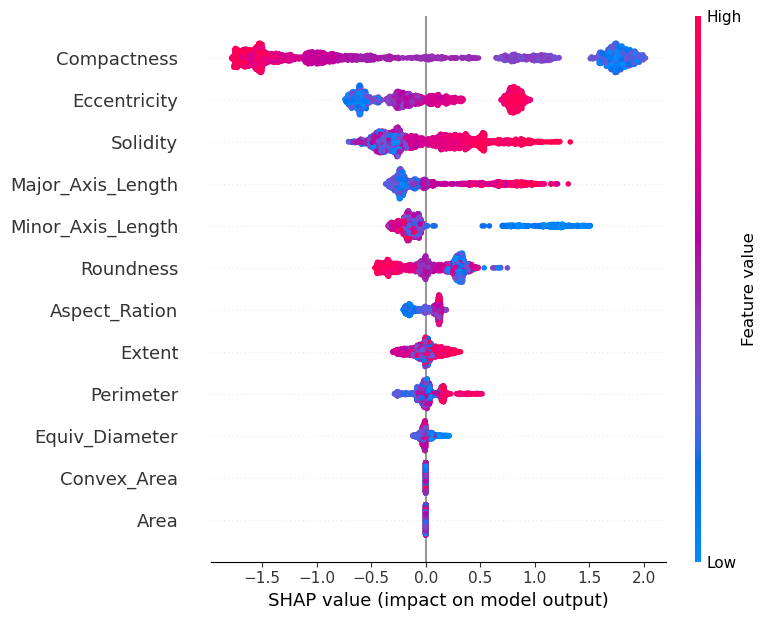

In [44]:
explainer = shap.TreeExplainer(xgb_pipe.named_steps['model'])
transformed_X = prep.transform(X_train)
shap_values = explainer.shap_values(transformed_X)
shap.summary_plot(shap_values, transformed_X,feature_names=feat)


In [ ]:
sorted(zip(feat,shap_values[0,0]), key=lambda x:abs(x[1]), reverse=True)[:5]
